# Task 14 — Implicit-feedback recommendations: what to show each visitor next

**Study unit:** ARI3217 — AI Enterprise Architectures and Transformation (University of Malta)
**Dataset:** [Retailrocket recommender system dataset](https://www.kaggle.com/datasets/retailrocket/ecommerce-dataset) (4.5 months of views, add-to-carts and purchases on a real online shop, weekly item-property snapshots, a category tree)
**Task family:** implicit-feedback recommendation, temporal evaluation, taxonomy as context, questions to SQL without an LLM · **Companion tasks:** `02_card_fraud_tabular.ipynb` (honest evaluation forward in time, drift) and `04_erp_document_rag.ipynb` (query understanding without an LLM)

---

## The task card

> **Board question.** *Seven visitors in ten leave after one page, and fewer than one in a hundred buys. A bestseller list in the 20 "you may also like" slots holds about 1 % of what visitors go on to look at. What should each visitor see next, and should some of the 20 slots go to new items nobody has clicked yet?*

**Business context.** Two Session 01 patterns meet: an *offline batch* that rebuilds an item-to-item neighbour table nightly, and *online prediction* when the page renders (`POST /recommend`). The legacy estate: the shop platform, the catalogue that owns categories and availability, and the analytics tag, behind a cookie banner, that writes the event log.

**What you will build from this notebook (see *Student tasks* at the end):**

1. the given **recommender**, packaged and reproducible, evaluated *forward in time* on the last two weeks, by segment and on cold items, with the traps guarded by tests;
2. an **operating point**: how many slots go to never-clicked items, chosen on validation weeks, in an ADR;
3. the **operational wrapper**: package, `POST /recommend`, CI gate on recall@20, registry, model card, monitoring;
4. a **category knowledge base** with SHACL and a cold-item ablation, and a **merchandiser question layer** over SQL.

**Where this sits in the unit**

| Block | What this task exercises |
|---|---|
| 1 · EA for AI | Nightly batch plus request-time scoring; catalogue and consent systems; GDPR and ePrivacy |
| 2 · MLOps | Forward evaluation by segment, a CI gate on a frozen fortnight, weekly retraining |
| 3 · Semantic layer | A SKOS taxonomy with SHACL; properties joined *as of* a date; a cold-item ablation |
| 4 · LLM/RAG | A merchandiser assistant over generated SQL, verified by re-running it |

**Assessment.** A *worked baseline plus tasks*; marks follow `docs/task-rubric.md`. The model is given: you are marked on how you package, evaluate, deploy, monitor and govern it, not on improving it. The notebook contains **deliberate traps**, each flagged with ⚠ in the text; turning each into a test is part of the task.

**Honesty note.** The data is **real**: a live shop's log, published by the vendor Retailrocket with identifiers and most property values hashed. We do not know what the shop showed visitors, so offline recall measures whether a model *would have shown* what a visitor went on to view, not whether showing it caused the view. An A/B test decides.

---

## How this notebook is organised

The notebook has three parts. Parts A and B are given; Part C is your assignment. **The model is given:** you package, evaluate, deploy and monitor it; you do not design, tune or replace it.

| Part | Sections | What it contains | What you do with it |
|---|---|---|---|
| **A · Explore the data** | 1–2 | Dataset card, the as-of rule and first look | Read. Its quirks go into your model card and data contract. |
| **B · The given model** | 3–5 | Three recommenders forward in time, category context and the new-item operating point, the traps | Read, then package the code unchanged and reproduce its numbers (C2). |
| **C · Productionise it** | 6–10 | The catalogue after deployment, the merchandiser question layer, the module spine, student tasks, hand-in checklist | Your work: package, test, gate, track, serve, monitor, govern. Section 6 shows the drift your monitoring must catch. |

**What you need from Parts A and B**

- **Code to package:** `get_raw`, `load_events`, `load_properties`, `asof` and `at_event_time` (Section 1); `make_window`, `recommend`, `evaluate`, `popularity`, `visitor_item_matrix`, `fit_knn`, `context_matrix` and `knn_cands` (Section 3); `category_tops`, `category_cands`, `cf_plus_category`, `serve` and `with_new_items` (Section 4); `psi_by_week` for monitoring (Section 6); `parse_period`, `parse` and `run_sql` (Section 7).
- **Parameters for `config/config.yaml`:** the CAPITALS in Section 0.
- **Numbers your pipeline must reproduce (C2):** test fortnight 4–18 Sep 2015: 143,689 active visitors, 24,532 scored, 56,202 target items (6.5 % cold); popularity look-back 14 days and history weight 0.25, chosen on validation; item-kNN recall@20 0.229, with category context 0.256 (NDCG@20 0.148), a gain of +0.027 (95 % interval +0.025 to +0.028); no new-item slot (R = 0) at `NEW_ITEM_VALUE` = 5.
- **Runtime:** about 4 minutes on a laptop (237 s on the build machine).

## 0 · Setup

*Before Part A · the parameters below move into `config/config.yaml`.*

In [1]:
%matplotlib inline
import os, re, json, time, hashlib, calendar, warnings
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import scipy
import scipy.sparse as sp
import matplotlib.pyplot as plt
import pyarrow as pa
import pyarrow.csv as pacsv
import pyarrow.compute as pc
import duckdb
import networkx as nx
import rdflib
import pyshacl
import sklearn
from rdflib import Graph, Namespace, RDF
from rdflib.namespace import SKOS
from sklearn.decomposition import TruncatedSVD
from threadpoolctl import threadpool_limits
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 20); pd.set_option("display.max_colwidth", 90)

# ---- parameters -------------------------------------------------------------
SEED = 3217
N_JOBS = 1                                 # BLAS and DuckDB threads (raise it on your own laptop)
KAGGLE_HANDLE = "retailrocket/ecommerce-dataset"
VALID_START = pd.Timestamp("2015-08-21")   # validation fortnight 21 Aug – 3 Sep: every choice below is made here
TEST_START = pd.Timestamp("2015-09-04")    # test fortnight 4 – 18 Sep: the last two weeks, the frozen CI holdout
DATA_END = pd.Timestamp("2015-09-18 03:00")  # end of the event log (all timestamps are UTC)
N_SLOTS = 20                               # recommendation slots on a product page (assumption — task C3)
EVENT_WEIGHT = np.array([1.0, 2.0, 3.0])   # view, add-to-cart, purchase as implicit feedback for popularity (assumption — task C2)
POP_WINDOWS_DAYS = (3, 7, 14, 28, 0)       # popularity look-back windows tried on validation (0 = all history)
KNN_NEIGHBOURS = 100                       # neighbours kept per item in the co-occurrence model
HISTORY_WEIGHTS = (0.0, 0.25, 1.0)         # weight of a returning visitor's earlier items against the seed; chosen on validation
MAX_ITEMS_PER_VISITOR = 200                # training visitors with more distinct items are left out of the models (Trap 3)
MF_RANK, MF_MIN_ITEM_VISITORS = 128, 10    # PureSVD rank and item support; fixed for runtime, not tuned (task C2)
NEW_ITEM_SLOTS = (0, 1, 2, 3, 4, 6)        # slots reserved for never-clicked items, chosen on validation (Section 4)
NEW_ITEM_VALUE = 5.0                       # a click on a never-clicked item, in ordinary clicks (assumption — task C3)
FREEZE_DATE = pd.Timestamp("2015-07-06")   # Section 6: a model frozen on this Monday, against one retrained every week
KEEP_PROPERTIES = ["categoryid", "available"]   # the only item properties kept from the 20 M property rows
PSEUDONYM_KEY = os.environ.get("RETAILROCKET_PSEUDONYM_KEY", "ari3217-task14-teaching-key").encode()   # production: a secret store, never in Git

DATA_DIR = Path(os.environ.get("DATASETS_TASKS_DATA", Path.cwd().parent.parent / "data"))
RAW, PROCESSED = DATA_DIR / "raw" / "retailrocket", DATA_DIR / "processed"
RAW.mkdir(parents=True, exist_ok=True); PROCESSED.mkdir(parents=True, exist_ok=True)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})
threadpool_limits(N_JOBS)
np.random.seed(SEED)
rng = np.random.default_rng(SEED)
T_START = time.time()
print(f"pandas {pd.__version__} · numpy {np.__version__} · scipy {scipy.__version__} · scikit-learn {sklearn.__version__} · "
      f"duckdb {duckdb.__version__} · rdflib {rdflib.__version__} · pyshacl {pyshacl.__version__}")

pandas 3.1.0 · numpy 2.5.4 · scipy 1.18.1 · scikit-learn 1.9.1 · duckdb 2.0.0 · rdflib 7.6.0 · pyshacl 0.40.1


# Part A — Explore the data

*Sections 1–2: read them; the quirks they find go into your model card and data contract.*

## 1 · Dataset card

*Part A · Explore · read; package the loaders and the as-of readers `asof` and `at_event_time`; C1 tests the as-of rule.*

| Field | Value |
|---|---|
| **Source** | Kaggle: `retailrocket/ecommerce-dataset`, published by Retailrocket from one unnamed client shop |
| **Licence** | CC BY-NC-SA 4.0: attribution, **non-commercial** use only, share-alike for derived data |
| **Provenance** | A live shop, 3 May – 18 Sep 2015; ids and all property values except `categoryid` and `available` hashed |
| **Size** | 2,756,101 events (1,407,580 visitors, 235,061 items); de-duplicated: 2,664,218 views, 68,966 add-to-carts, 22,457 purchases in 17,672 orders. 20,275,902 property rows on 417,053 items. 987 MB |
| **Files** | `events.csv` (94 MB), `item_properties_part1.csv` (484 MB), `item_properties_part2.csv` (409 MB), `category_tree.csv` |
| **Schema** | events: `timestamp` (ms), `visitorid`, `event`, `itemid`, `transactionid`; properties: `timestamp`, `itemid`, `property` (1,104 codes), `value`; tree: `categoryid`, `parentid` |
| **Label** | None: implicit feedback; a later interaction is a positive, its absence *not* a negative |
| **Window used here** | All events; validation 21 Aug – 3 Sep, test 4 – 18 Sep (the frozen holdout). Properties: only `categoryid` and `available` (2.3 M rows), streamed in 32 MB blocks |
| **PII** | `visitorid` is a pseudonymous cookie-level id, personal data under GDPR if it can be linked back (Recital 26). Replaced on load by a keyed hash; the default teaching key is public, so production sets `RETAILROCKET_PSEUDONYM_KEY` from a secret store |

**Known quirks you must handle (and should mention in your model card):**

1. ⚠ **Properties are weekly snapshots.** Eighteen Sundays (10 May – 13 Sep; 21 June missing); 23,352 items change category and 67,001 availability; 5 % of events precede the first snapshot. A join that ignores the date reads the future (Trap 1).
2. **23.8 % of events have no category at the time** (9.3 % never get one): items enter the property log late.
3. ⚠ **Some visitors are not shoppers.** 118 visitors with more than 200 distinct items make 23 % of all purchases; resellers, staff or scrapers, the hashed ids cannot tell (Trap 3).
4. **71 % of visitors produce one event**: most recommendations must work from the current page.
5. **460 exact duplicate events** (366 add-to-carts) are dropped on load.
6. **The tree is a forest of 25 roots**; 30 categories used by items are missing from it.
7. **The log was probably produced under some recommender** (the shop was a vendor's client); offline metrics inherit its bias.

In [2]:
EVENTS = ["view", "addtocart", "transaction"]          # stored as codes 0, 1, 2

def get_raw(filename: str) -> Path:
    local = RAW / filename
    if local.exists():
        return local
    import kagglehub
    return Path(kagglehub.dataset_download(KAGGLE_HANDLE, path=filename))

def load_events() -> tuple[pd.DataFrame, dict]:
    '''All events, exact duplicates dropped, visitors pseudonymised with a keyed hash; cached as Parquet.'''
    cache, meta = PROCESSED / "14_events.parquet", PROCESSED / "14_events_meta.json"
    key_id = hashlib.sha256(PSEUDONYM_KEY).hexdigest()[:8]                # which key made the cache (never the key itself)
    if cache.exists() and meta.exists() and json.load(open(meta)).get("key_id") == key_id:
        return pd.read_parquet(cache), json.load(open(meta))
    raw = pd.read_csv(get_raw("events.csv"), dtype={"timestamp": "int64", "visitorid": "int64", "event": "category",
                                                     "itemid": "int32", "transactionid": "float64"})
    n_raw = len(raw)
    dup = raw.duplicated(["timestamp", "visitorid", "event", "itemid"])
    dup_by_type = raw.loc[dup, "event"].astype(str).value_counts().to_dict()
    raw = raw[~dup]
    # ---- governance on load: keyed BLAKE2b of the source id, then its rank → an int32 pseudonym; the source id is dropped.
    # Without PSEUDONYM_KEY the mapping cannot be rebuilt; with the default teaching key, anyone holding the notebook can.
    ids = np.unique(raw.visitorid.values)
    digest = np.array([int.from_bytes(hashlib.blake2b(str(i).encode(), key=PSEUDONYM_KEY, digest_size=8).digest(), "big") for i in ids], dtype=np.uint64)
    pseudonym = np.empty(len(ids), np.int32); pseudonym[np.argsort(digest, kind="stable")] = np.arange(len(ids), dtype=np.int32)
    ev = pd.DataFrame({"ts": pd.to_datetime(raw.timestamp.values, unit="ms"),
                       "visitor": pseudonym[np.searchsorted(ids, raw.visitorid.values)],
                       "ev": raw.event.astype(str).map({e: i for i, e in enumerate(EVENTS)}).astype(np.int8).values,
                       "itemid": raw.itemid.values,
                       "order_id": raw.transactionid.astype("Int32").values})
    ev = ev.sort_values(["ts", "visitor"], kind="stable").reset_index(drop=True)
    ev.to_parquet(cache)
    m = {"raw_rows": n_raw, "duplicates": n_raw - len(ev), "duplicates_by_type": dup_by_type, "key_id": key_id}
    json.dump(m, open(meta, "w"))
    return ev, m

def load_properties() -> tuple[pd.DataFrame, dict]:
    '''Stream both property files in 32 MB blocks and keep only KEEP_PROPERTIES; cached as Parquet.'''
    cache, meta = PROCESSED / "14_item_properties.parquet", PROCESSED / "14_item_properties_meta.json"
    if cache.exists() and meta.exists():
        return pd.read_parquet(cache), json.load(open(meta))
    opts = pacsv.ConvertOptions(column_types={"timestamp": pa.int64(), "itemid": pa.int32(), "property": pa.string(), "value": pa.string()})
    keep, rows, codes, snapshots, items = [], 0, set(), set(), set()
    for f in ["item_properties_part1.csv", "item_properties_part2.csv"]:
        for batch in pacsv.open_csv(get_raw(f), read_options=pacsv.ReadOptions(block_size=32 << 20), convert_options=opts):
            rows += batch.num_rows
            codes.update(pc.unique(batch["property"]).to_pylist()); snapshots.update(pc.unique(batch["timestamp"]).to_pylist())
            items.update(pc.unique(batch["itemid"]).to_pylist())
            keep.append(batch.filter(pc.is_in(batch["property"], value_set=pa.array(KEEP_PROPERTIES))).to_pandas())
    p = pd.concat(keep, ignore_index=True)
    props = pd.DataFrame({"ts": pd.to_datetime(p.timestamp.values, unit="ms"), "itemid": p.itemid.values.astype(np.int32),
                          "prop": p.property.astype("category").values, "value": p.value.astype(np.int32).values})
    props = props.sort_values(["ts", "itemid"], kind="stable").reset_index(drop=True)
    props.to_parquet(cache)
    m = {"rows": rows, "items": len(items), "codes": len(codes), "snapshots": sorted(snapshots)}
    json.dump(m, open(meta, "w"))
    return props, m

t0 = time.time()
ev, ev_meta = load_events()
props, prop_meta = load_properties()
tree = pd.read_csv(get_raw("category_tree.csv")).astype({"categoryid": "int32"})
snaps = pd.to_datetime(prop_meta["snapshots"], unit="ms")
n_by = ev.ev.value_counts().sort_index()
sizes = {f: get_raw(f).stat().st_size / 1e6 for f in ["events.csv", "item_properties_part1.csv", "item_properties_part2.csv", "category_tree.csv"]}
print("raw files: " + " · ".join(f"{f} {mb:,.1f} MB" for f, mb in sizes.items()) + f" · total {sum(sizes.values()):,.0f} MB")
print(f"events: {ev_meta['raw_rows']:,} rows, {ev_meta['duplicates']:,} exact duplicates dropped {ev_meta['duplicates_by_type']} → {len(ev):,} "
      f"({n_by[0]:,} views · {n_by[1]:,} add-to-carts · {n_by[2]:,} purchases in {ev.order_id.nunique():,} orders) · "
      f"{ev.visitor.nunique():,} visitors · {ev.itemid.nunique():,} items · {ev.ts.min():%d %b %Y %H:%M} – {ev.ts.max():%d %b %Y %H:%M} UTC")
print(f"item properties: {prop_meta['rows']:,} rows on {prop_meta['items']:,} items, {prop_meta['codes']:,} property codes, "
      f"{len(snaps)} weekly snapshots ({snaps.min():%a %d %b} – {snaps.max():%a %d %b}); kept {len(props):,} rows of {KEEP_PROPERTIES}")
gaps = snaps.to_series().diff().dt.days
print(f"snapshot gaps other than 7 days: {[f'{a:%d %b} → {b:%d %b}' for a, b, g in zip(snaps[:-1], snaps[1:], gaps[1:]) if g != 7]}")
print(f"category tree: {len(tree):,} categories, {tree.parentid.isna().sum()} roots · loaded in {time.time()-t0:.0f}s · "
      f"memory {(ev.memory_usage(deep=True).sum() + props.memory_usage(deep=True).sum())/1e6:.0f} MB")

raw files: events.csv 94.2 MB · item_properties_part1.csv 484.3 MB · item_properties_part2.csv 408.9 MB · category_tree.csv 0.0 MB · total 987 MB
events: 2,756,101 rows, 460 exact duplicates dropped {'addtocart': 366, 'view': 94} → 2,755,641 (2,664,218 views · 68,966 add-to-carts · 22,457 purchases in 17,672 orders) · 1,407,580 visitors · 235,061 items · 03 May 2015 03:00 – 18 Sep 2015 02:59 UTC
item properties: 20,275,902 rows on 417,053 items, 1,104 property codes, 18 weekly snapshots (Sun 10 May – Sun 13 Sep); kept 2,291,853 rows of ['categoryid', 'available']
snapshot gaps other than 7 days: ['14 Jun → 28 Jun']
category tree: 1,669 categories, 25 roots · loaded in 0s · memory 100 MB


**The as-of rule, written once.** Later cells read item properties only through `asof(prop, at)` (what a nightly batch knows at a cutoff) or `at_event_time(prop)` (what the shop knew at each event). `latest()`, the careless join, exists only for Trap 1.

In [3]:
def asof(prop: str, at) -> pd.Series:
    '''Item → value in the latest weekly snapshot at or before `at`.'''
    p = props[(props.prop == prop) & (props.ts <= at)]
    return p.groupby("itemid").value.last()             # props is sorted by time

def latest(prop: str) -> pd.Series:
    '''⚠ Item → value in the last snapshot of the file, whatever the date of the event. Trap 1 only.'''
    return props[props.prop == prop].groupby("itemid").value.last()

def at_event_time(prop: str) -> np.ndarray:
    '''For every event, the item's value in the latest snapshot at or before the event (-1 = no snapshot yet).'''
    p = props.loc[props.prop == prop, ["ts", "itemid", "value"]]
    m = pd.merge_asof(ev[["ts", "itemid"]], p, on="ts", by="itemid", direction="backward")
    return m.value.fillna(-1).astype(np.int32).values

listed = props[props.prop == "categoryid"].groupby("itemid").ts.min()     # first snapshot an item appears in
ev["cat"] = at_event_time("categoryid")
ev["avail"] = at_event_time("available").astype(np.int8)
n_cat_changed = (props[props.prop == "categoryid"].groupby("itemid").value.nunique() > 1).sum()
n_av_changed = (props[props.prop == "available"].groupby("itemid").value.nunique() > 1).sum()
print(f"events before the first snapshot: {(ev.ts < snaps.min()).mean():.1%} · events whose item has no category at that time: {(ev.cat < 0).mean():.1%} "
      f"(no category ever: {(~ev.itemid.isin(listed.index)).mean():.1%}) · items whose category changes: {n_cat_changed:,}, availability: {n_av_changed:,}")
print(f"categories used by items but missing from the tree: {len(set(props.loc[props.prop == 'categoryid', 'value']) - set(tree.categoryid))}")

events before the first snapshot: 5.0% · events whose item has no category at that time: 23.8% (no category ever: 9.3%) · items whose category changes: 23,352, availability: 67,001
categories used by items but missing from the tree: 30


## 2 · First look: a long tail on both sides

*Part A · Explore · read; one-page visitors and the 118 heavy visitors go into the model card and E4.*

What a merchandiser asks first: who does anything at all, and how concentrated is the catalogue?

,all 4.5 months
visitors,"1,407,580"
with a single event,71.2%
active on more than one day,10.2%
added anything to a cart,2.68%
bought anything,0.83%
views per add-to-cart,38.6
items with a single event,31.3%
events on the top 1 % of items,22.9%


visitors with more than 200 distinct items: 118 (0.008% of visitors) · 4.0% of events · 23.0% of purchases


,events,carts,purchases,items,days
visitor (pseudonym),,,,,
1195129,7757,719,559,3814,74
361698,4328,419,286,2209,73
742211,3024,371,349,1622,38
943258,2474,56,50,1641,97
145262,2410,124,92,1314,21


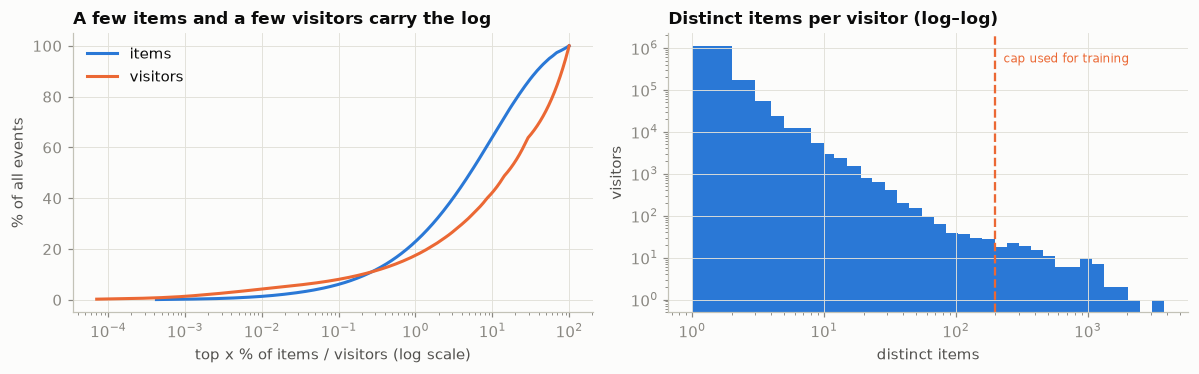

In [4]:
vs = ev.assign(cart=ev.ev == 1, buy=ev.ev == 2).groupby("visitor").agg(events=("ev", "size"), carts=("cart", "sum"), purchases=("buy", "sum"))
vs["items"] = ev.groupby("visitor").itemid.nunique()
vs["days"] = ev.assign(d=ev.ts.dt.floor("D")).groupby("visitor").d.nunique()
item_n = ev.groupby("itemid").size().sort_values(ascending=False)
funnel = pd.Series({
    "visitors": f"{len(vs):,}",
    "with a single event": f"{(vs.events == 1).mean():.1%}",
    "active on more than one day": f"{(vs.days > 1).mean():.1%}",
    "added anything to a cart": f"{(vs.carts > 0).mean():.2%}",
    "bought anything": f"{(vs.purchases > 0).mean():.2%}",
    "views per add-to-cart": f"{n_by[0] / n_by[1]:.1f}",
    "items with a single event": f"{(item_n == 1).mean():.1%}",
    "events on the top 1 % of items": f"{item_n.head(len(item_n) // 100).sum() / len(ev):.1%}",
})
display(funnel.to_frame("all 4.5 months"))
heavy = vs[vs["items"] > MAX_ITEMS_PER_VISITOR]
print(f"visitors with more than {MAX_ITEMS_PER_VISITOR} distinct items: {len(heavy):,} ({len(heavy)/len(vs):.3%} of visitors) · "
      f"{heavy.events.sum()/len(ev):.1%} of events · {heavy.purchases.sum()/n_by[2]:.1%} of purchases")
display(vs.sort_values("events", ascending=False).head(5).rename_axis("visitor (pseudonym)"))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
ax = axes[0]
for counts, lab_, color in [(item_n.values, "items", SERIES[0]), (vs.events.sort_values(ascending=False).values, "visitors", SERIES[1])]:
    ax.plot(np.arange(1, len(counts) + 1) / len(counts) * 100, np.cumsum(counts) / counts.sum() * 100, lw=2, color=color, label=lab_)
ax.set_xscale("log"); ax.set_xlabel("top x % of items / visitors (log scale)"); ax.set_ylabel("% of all events")
ax.set_title("A few items and a few visitors carry the log"); ax.legend()
ax = axes[1]
bins = np.unique(np.logspace(0, np.log10(vs["items"].max() + 1), 40).astype(int))
ax.hist(vs["items"], bins=bins, color=SERIES[0]); ax.set_xscale("log"); ax.set_yscale("log")
ax.axvline(MAX_ITEMS_PER_VISITOR, color=SERIES[1], ls="--", lw=1.5)
ax.text(MAX_ITEMS_PER_VISITOR * 1.15, ax.get_ylim()[1] * 0.2, "cap used for training", color=SERIES[1], fontsize=8)
ax.set_title("Distinct items per visitor (log–log)"); ax.set_xlabel("distinct items"); ax.set_ylabel("visitors")
plt.tight_layout()

Most visitors give a recommender one page to work with. The heaviest touched 3,814 distinct items over 74 days and bought 559 times — hardly the audience for a "you may also like" strip.

# Part B — The given model

*Sections 3–5: read them, then package the code unchanged and reproduce its numbers (C2). You do not change the method.*

## 3 · Three recommenders, evaluated forward in time

*Part B · Given model · package `make_window`, `evaluate`, `fit_knn` and `knn_cands` unchanged and reproduce the numbers (C2); PureSVD is reference only.*

**The protocol.** In each evaluation fortnight, a visitor's *seed* is their first page, where the strip renders; the *context* is the seed plus earlier history; the *target* is every other item they view, cart or buy later in the fortnight and had not touched before. Visitors who never go past the seed are not scored. Models train only on what came before.

**The metrics.** recall@20 is the share of a visitor's next items found in the 20 slots, averaged over visitors; NDCG@20 also rewards ranking them high. Segments: *new* and *returning* visitors, *cold* seeds (no earlier events), carted and cold target items.

**The models.** *Popularity*: weighted event counts over a look-back window. *Item-kNN*: cosine similarity from visitor co-occurrence, 100 neighbours per item, scored from the seed and, at a weight chosen on validation, the visitor's history (Linden et al., 2003). *PureSVD*: a rank-128 truncated SVD of the visitor × item matrix, context folded in (Cremonesi et al., 2010); implicit ALS (Hu et al., 2008) is not used here. Popularity fills empty slots.

In [5]:
KEY = lambda v, i: (np.asarray(v, dtype=np.int64) << 20) | np.asarray(i, dtype=np.int64)   # a (visitor, item) pair as one integer

def make_window(tr: pd.DataFrame, te: pd.DataFrame, name: str) -> SimpleNamespace:
    '''Seeded protocol. Seed = the visitor's first event in the window; context = the seed plus everything the visitor
    did before the window; target = every other item they view, cart or buy later in the window.'''
    te = te.sort_values(["visitor", "ts"], kind="stable")
    v, it = te.visitor.values, te.itemid.values
    first = np.r_[True, v[1:] != v[:-1]]
    seed_of = pd.Series(it[first], index=v[first])
    hist = tr.loc[tr.visitor.isin(seed_of.index), ["visitor", "itemid"]].drop_duplicates()
    later = (~first) & (it != seed_of.reindex(v).values) & ~pd.Index(KEY(v, it)).isin(KEY(hist.visitor, hist.itemid))
    tg = (pd.DataFrame({"visitor": v[later], "itemid": it[later], "cart": te.ev.values[later] > 0})
          .groupby(["visitor", "itemid"], sort=False).cart.max().reset_index())
    warm = pd.Index(tr.itemid.unique())
    tg["cold"] = ~tg.itemid.isin(warm)
    vis = pd.DataFrame({"visitor": tg.visitor.unique()})
    vis["seed"] = seed_of.reindex(vis.visitor).values
    vis["returning"] = vis.visitor.isin(hist.visitor.unique())
    vis["seed_cold"] = ~vis.seed.isin(warm)
    hist = hist[hist.visitor.isin(vis.visitor)]
    excl = pd.Index(np.r_[KEY(vis.visitor, vis.seed), KEY(hist.visitor, hist.itemid)])   # never recommend the context back
    return SimpleNamespace(name=name, tr=tr, vis=vis, tg=tg, hist=hist, excl=excl, warm=warm, n_active=len(seed_of))

def recommend(w, cands, pop_items, n=N_SLOTS) -> pd.DataFrame:
    '''Merge candidate lists (row, item, priority; lower is better), drop the context and duplicates, pad with popularity, keep n.'''
    P = np.asarray(pop_items[: n + 40])
    cands = list(cands) + [(np.repeat(np.arange(len(w.vis)), len(P)), np.tile(P, len(w.vis)), np.tile(1e6 + np.arange(len(P)), len(w.vis)))]
    rows, items, prio = (np.concatenate(x) for x in zip(*cands))
    k = KEY(w.vis.visitor.values[rows], items)
    keep = ~pd.Index(k).isin(w.excl)
    rows, items, prio, k = rows[keep], items[keep], prio[keep], k[keep]
    o = np.lexsort((items, prio, rows)); rows, items, k = rows[o], items[o], k[o]     # ties broken by item id
    first = ~pd.Index(k).duplicated()
    rows, items = rows[first], items[first]
    rank = pd.Series(rows).groupby(rows).cumcount().values
    s = rank < n
    return pd.DataFrame({"visitor": w.vis.visitor.values[rows[s]], "itemid": items[s], "rank": rank[s]})

def evaluate(w, rec, n=N_SLOTS) -> tuple[dict, pd.DataFrame, pd.DataFrame]:
    t = w.tg.merge(rec, on=["visitor", "itemid"], how="left")
    t["hit"] = t["rank"].notna()
    t["gain"] = np.where(t.hit, 1 / np.log2(t["rank"].fillna(0) + 2), 0.0)
    per = t.groupby("visitor").agg(n=("hit", "size"), hits=("hit", "sum"), dcg=("gain", "sum"))
    per["recall"] = per.hits / per.n
    per["ndcg"] = per.dcg / np.cumsum(1 / np.log2(np.arange(n) + 2))[np.minimum(per.n.values, n) - 1]
    per = per.join(w.vis.set_index("visitor")[["returning", "seed_cold"]])
    out = {"recall@20": per.recall.mean(), "NDCG@20": per.ndcg.mean(),
           "recall@20 · new visitors": per.loc[~per.returning, "recall"].mean(),
           "recall@20 · returning": per.loc[per.returning, "recall"].mean(),
           "recall@20 · cold seed": per.loc[per.seed_cold, "recall"].mean(),
           "hit rate · carted items": t.loc[t.cart, "hit"].mean(), "hit rate · cold items": t.loc[t.cold, "hit"].mean(),
           "items shown": rec.itemid.nunique()}
    return out, per, t

# ---- the three models ----------------------------------------------------------------------------------------------
def popularity(tr, at, days) -> pd.Index:
    t = tr[tr.ts >= at - pd.Timedelta(days=days)] if days else tr
    return pd.Series(EVENT_WEIGHT[t.ev.values]).groupby(t.itemid.values).sum().sort_values(ascending=False, kind="stable").index

def visitor_item_matrix(tr, cap, min_item_visitors=1):
    pairs = tr[["visitor", "itemid"]].drop_duplicates()
    nv = pairs.groupby("visitor").size()
    keep_v = nv[(nv >= 2) & ((nv <= cap) if cap else True)].index
    pairs = pairs[pairs.visitor.isin(keep_v)]
    if min_item_visitors > 1:
        ni = pairs.groupby("itemid").size()
        pairs = pairs[pairs.itemid.isin(ni[ni >= min_item_visitors].index)]
    items = np.sort(pairs.itemid.unique()); vids = np.sort(pairs.visitor.unique())
    X = sp.csr_matrix((np.ones(len(pairs), np.float32), (np.searchsorted(vids, pairs.visitor.values), np.searchsorted(items, pairs.itemid.values))),
                      shape=(len(vids), len(items)))
    return X, items

def fit_knn(tr, cap=MAX_ITEMS_PER_VISITOR, k=KNN_NEIGHBOURS, blocks=8):
    '''Item-item cosine on visitor co-occurrence, top-k neighbours per item; computed in item blocks to bound memory.'''
    X, items = visitor_item_matrix(tr, cap)
    deg = np.asarray(X.sum(0)).ravel(); Xc = X.tocsc()
    R, C, V = [], [], []
    edges = np.linspace(0, len(items), blocks + 1).astype(int)
    for a, b in zip(edges[:-1], edges[1:]):
        B = (Xc[:, a:b].T @ X).tocsr()
        r = np.repeat(np.arange(b - a), np.diff(B.indptr)); c = B.indices; v = B.data / np.sqrt(deg[r + a] * deg[c])
        off = c != r + a; r, c, v = r[off], c[off], v[off]
        cnt = np.bincount(r, minlength=b - a); heavy = cnt[r] > k
        if heavy.any():                                    # sort only the rows that have more than k neighbours
            hr, hc, hv = r[heavy], c[heavy], v[heavy]
            o = np.lexsort((hc, -hv, hr)); hr, hc, hv = hr[o], hc[o], hv[o]
            s = (np.arange(len(hr)) - np.searchsorted(hr, hr)) < k
            r, c, v = np.r_[r[~heavy], hr[s]], np.r_[c[~heavy], hc[s]], np.r_[v[~heavy], hv[s]]
        R.append(r + a); C.append(c); V.append(v.astype(np.float32))
        del B
    S = sp.csr_matrix((np.concatenate(V), (np.concatenate(R), np.concatenate(C))), shape=(len(items), len(items)))
    return SimpleNamespace(S=S, items=items, n_visitors=X.shape[0])

def context_matrix(w, items, w_hist):
    pos = pd.Series(np.arange(len(items)), index=items)
    vpos = pd.Series(np.arange(len(w.vis)), index=w.vis.visitor.values)
    rows = np.r_[np.arange(len(w.vis)), vpos.reindex(w.hist.visitor.values).values]
    cols = np.r_[pos.reindex(w.vis.seed.values).values, pos.reindex(w.hist.itemid.values).values]
    vals = np.r_[np.ones(len(w.vis)), np.full(len(w.hist), w_hist)]
    ok = ~np.isnan(cols) & (vals > 0)
    return sp.csr_matrix((vals[ok].astype(np.float32), (rows[ok], cols[ok].astype(int))), shape=(len(w.vis), len(items)))

def knn_cands(w, m, w_hist):
    sc = (context_matrix(w, m.items, w_hist) @ m.S).tocoo()
    return [(sc.row.astype(np.int64), m.items[sc.col], -sc.data.astype(np.float64))]

def fit_puresvd(tr, rank=MF_RANK, min_item_visitors=MF_MIN_ITEM_VISITORS, cap=MAX_ITEMS_PER_VISITOR):
    '''PureSVD: truncated SVD of the binary visitor × item matrix; items become rank-k vectors.'''
    X, items = visitor_item_matrix(tr, cap, min_item_visitors)
    svd = TruncatedSVD(n_components=rank, algorithm="randomized", n_iter=3, random_state=SEED).fit(X)
    return SimpleNamespace(V=np.ascontiguousarray(svd.components_.T, dtype=np.float32), items=items, shape=X.shape)

def svd_cands(w, m, w_hist, batch=512, depth=40):
    '''Fold the context into the factor space and score every item, (q · V) · Vᵀ, a batch of visitors at a time.'''
    Q = context_matrix(w, m.items, w_hist)
    rows, items, prio = [], [], []
    for s in range(0, Q.shape[0], batch):
        sc = np.asarray(Q[s:s + batch] @ m.V, dtype=np.float32) @ m.V.T
        top = np.argpartition(sc, -depth, axis=1)[:, -depth:]
        rows.append(np.repeat(np.arange(s, s + len(top)), depth)); items.append(m.items[top.ravel()])
        prio.append(-np.take_along_axis(sc, top, 1).ravel().astype(np.float64))
    has_ctx = np.diff(Q.indptr) > 0                        # no context in the factor space → leave the slots to popularity
    rows, items, prio = np.concatenate(rows), np.concatenate(items), np.concatenate(prio)
    k = has_ctx[rows]
    return [(rows[k], items[k], prio[k])]

def table(rows: dict):
    df = pd.DataFrame(rows).T
    return df.style.format({c: ("{:,.0f}" if c == "items shown" else "{:.3f}") for c in df.columns})

t0 = time.time()
VAL = make_window(ev[ev.ts < VALID_START], ev[(ev.ts >= VALID_START) & (ev.ts < TEST_START)], "validation")
TEST = make_window(ev[ev.ts < TEST_START], ev[ev.ts >= TEST_START], "test")
for w in (VAL, TEST):
    print(f"{w.name:10s} {w.n_active:,} active visitors → {len(w.vis):,} scored ({len(w.vis)/w.n_active:.0%}; the rest never went past the seed) · "
          f"returning {w.vis.returning.mean():.1%} · cold seed {w.vis.seed_cold.mean():.1%} · {len(w.tg):,} target items, "
          f"{w.tg.cold.mean():.1%} cold, {w.tg.cart.sum():,} carted or bought")
HOLDOUT_SHA256 = hashlib.sha256(pd.concat([TEST.vis[["visitor", "seed"]].rename(columns={"seed": "itemid"}).assign(role="seed"),
                                            TEST.tg[["visitor", "itemid"]].assign(role="target")]).to_csv(index=False).encode()).hexdigest()
SNAPSHOT_SHA256 = hashlib.sha256(props[props.ts <= TEST_START].to_csv(index=False).encode()).hexdigest()
print(f"frozen test fortnight for the CI gate: SHA-256 {HOLDOUT_SHA256[:16]}… · property snapshot as of {TEST_START:%d %b}: SHA-256 {SNAPSHOT_SHA256[:16]}… · "
      f"windows built in {time.time()-t0:.1f}s")

validation 141,559 active visitors → 23,555 scored (17%; the rest never went past the seed) · returning 15.1% · cold seed 5.0% · 53,691 target items, 6.3% cold, 3,176 carted or bought
test       143,689 active visitors → 24,532 scored (17%; the rest never went past the seed) · returning 15.6% · cold seed 5.2% · 56,202 target items, 6.5% cold, 3,208 carted or bought


frozen test fortnight for the CI gate: SHA-256 b8bd4e5b5fb7d7d5… · property snapshot as of 04 Sep: SHA-256 acd6e77ff9c07ec0… · windows built in 5.7s


Only 17 % of active visitors go past their first page, and about one in six of those has history. Cold items are 6.5 % of test targets, out of reach of any collaborative model. Validation chooses the popularity look-back and the history weight.

In [6]:
t0 = time.time()
val_rows = {}
for d in POP_WINDOWS_DAYS:
    val_rows[f"popularity · {d or 'all'} days"] = evaluate(VAL, recommend(VAL, [], popularity(VAL.tr, VALID_START, d)))[0]
POP_DAYS = max(POP_WINDOWS_DAYS, key=lambda d: val_rows[f"popularity · {d or 'all'} days"]["recall@20"])
pop_val = popularity(VAL.tr, VALID_START, POP_DAYS)
knn_val = fit_knn(VAL.tr)
for wh in HISTORY_WEIGHTS:
    val_rows[f"item-kNN · history weight {wh}"] = evaluate(VAL, recommend(VAL, knn_cands(VAL, knn_val, wh), pop_val))[0]
W_HIST = max(HISTORY_WEIGHTS, key=lambda wh: val_rows[f"item-kNN · history weight {wh}"]["recall@20"])
mf_val = fit_puresvd(VAL.tr)
val_rows["PureSVD (fixed rank, for comparison)"] = evaluate(VAL, recommend(VAL, svd_cands(VAL, mf_val, W_HIST), pop_val))[0]
del mf_val
display(table(val_rows))
print(f"chosen on validation: popularity look-back {POP_DAYS} days · history weight {W_HIST} · ({time.time()-t0:.0f}s)")

,recall@20,NDCG@20,recall@20 · new visitors,recall@20 · returning,recall@20 · cold seed,hit rate · carted items,hit rate · cold items,items shown
popularity · 3 days,0.012,0.005,0.013,0.009,0.009,0.012,0.000,45
popularity · 7 days,0.013,0.006,0.014,0.010,0.008,0.015,0.000,47
popularity · 14 days,0.014,0.006,0.014,0.011,0.009,0.016,0.000,47
popularity · 28 days,0.012,0.005,0.013,0.009,0.008,0.015,0.000,47
popularity · all days,0.009,0.003,0.009,0.005,0.003,0.010,0.000,44
item-kNN · history weight 0.0,0.232,0.137,0.245,0.154,0.009,0.123,0.000,"71,605"
item-kNN · history weight 0.25,0.232,0.137,0.245,0.156,0.009,0.122,0.000,"74,100"
item-kNN · history weight 1.0,0.228,0.134,0.245,0.130,0.009,0.120,0.000,"75,032"
"PureSVD (fixed rank, for comparison)",0.096,0.056,0.101,0.069,0.010,0.070,0.000,"1,904"


chosen on validation: popularity look-back 14 days · history weight 0.25 · (32s)


In [7]:
t0 = time.time()
pop_test = popularity(TEST.tr, TEST_START, POP_DAYS)
knn = fit_knn(TEST.tr)
t_knn = time.time() - t0
mf = fit_puresvd(TEST.tr)
t_mf = time.time() - t0 - t_knn
REC = {"popularity": recommend(TEST, [], pop_test),
       "item-kNN (co-occurrence)": recommend(TEST, knn_cands(TEST, knn, W_HIST), pop_test)}
t1 = time.time()
REC["PureSVD (matrix factorisation)"] = recommend(TEST, svd_cands(TEST, mf, W_HIST), pop_test)
t_mf_score = time.time() - t1
res = {name: evaluate(TEST, rec)[0] for name, rec in REC.items()}
display(table(res))
print(f"fit: item-kNN {t_knn:.0f}s on {knn.n_visitors:,} visitors × {len(knn.items):,} items ({knn.S.nnz:,} neighbour links) · "
      f"PureSVD {t_mf:.0f}s on {mf.shape[0]:,} × {mf.shape[1]:,}, scoring {t_mf_score:.0f}s")

,recall@20,NDCG@20,recall@20 · new visitors,recall@20 · returning,recall@20 · cold seed,hit rate · carted items,hit rate · cold items,items shown
popularity,0.012,0.005,0.013,0.009,0.003,0.013,0.000,47
item-kNN (co-occurrence),0.229,0.138,0.242,0.159,0.008,0.121,0.000,"78,118"
PureSVD (matrix factorisation),0.092,0.054,0.096,0.067,0.006,0.065,0.000,"1,836"


fit: item-kNN 4s on 260,310 visitors × 144,213 items (3,689,919 neighbour links) · PureSVD 10s on 217,018 × 20,555, scoring 7s


item-kNN recall@20 by the seed's neighbour count: {'0': '0.007 (n=2,618)', '1–4': '0.134 (n=2,347)', '5–19': '0.274 (n=3,444)', '20–99': '0.286 (n=5,968)', '100': '0.260 (n=10,155)'}


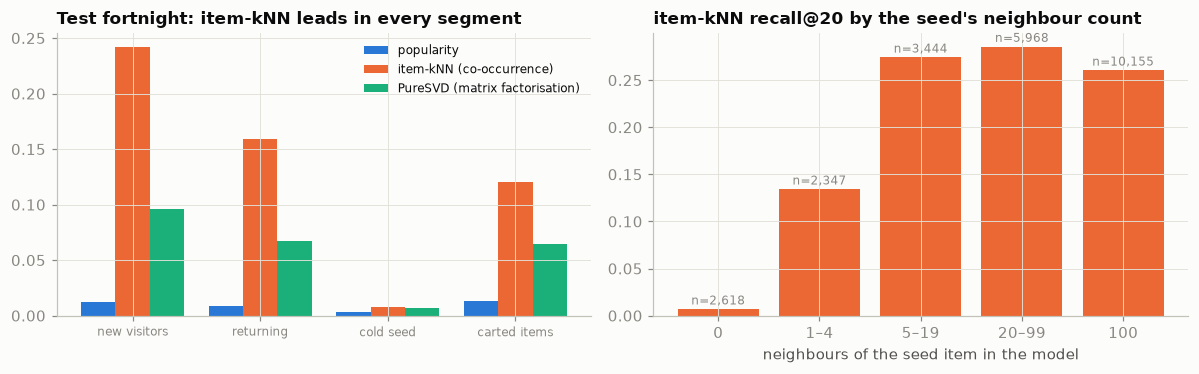

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
ax = axes[0]
segs = ["recall@20 · new visitors", "recall@20 · returning", "recall@20 · cold seed", "hit rate · carted items"]
x = np.arange(len(segs))
for j, (name, color) in enumerate(zip(res, SERIES)):
    ax.bar(x + (j - 1) * 0.27, [res[name][s] for s in segs], width=0.27, color=color, label=name)
ax.set_xticks(x); ax.set_xticklabels([s.split(" · ")[1] for s in segs], fontsize=8)
ax.set_title("Test fortnight: item-kNN leads in every segment"); ax.legend(fontsize=8)
ax = axes[1]
_, per_knn, _ = evaluate(TEST, REC["item-kNN (co-occurrence)"])
nn_links = pd.Series(np.diff(knn.S.indptr), index=knn.items)
per_knn["seed links"] = nn_links.reindex(TEST.vis.set_index("visitor").seed.reindex(per_knn.index).values).fillna(0).values
bands = pd.cut(per_knn["seed links"], [-1, 0, 4, 19, 99, 1e9], labels=["0", "1–4", "5–19", "20–99", "100"])
g = per_knn.groupby(bands, observed=True).recall.agg(["mean", "size"])
ax.bar(g.index.astype(str), g["mean"], color=SERIES[1])
for i, (m_, n_) in enumerate(zip(g["mean"], g["size"])):
    ax.text(i, m_ + 0.005, f"n={n_:,}", ha="center", fontsize=8, color=MUTED)
ax.set_title("item-kNN recall@20 by the seed's neighbour count"); ax.set_xlabel("neighbours of the seed item in the model")
plt.tight_layout()
print("item-kNN recall@20 by the seed's neighbour count:", {k: f"{v:.3f} (n={n:,})" for k, v, n in zip(g.index.astype(str), g["mean"], g["size"])})

Item-kNN finds 22.9 % of what a visitor goes on to view: 19 times popularity (1.2 %) and 2.5 times PureSVD (9.2 %), the same order as on validation (0.232 against 0.096). The factor model is compressed, not broken: one seed folded into 128 dimensions loses the long tail, and it shows 1,836 distinct items in all against item-kNN's 78,118. Neighbourhood methods are known to be hard to beat on next-item tasks (Ludewig and Jannach, 2018). Returning visitors are harder (0.159 against 0.242). The right panel shows the limit: for the 2,618 visitors whose seed has no neighbours, recall is 0.7 %.

## 4 · Category context, cold items and the operating point

*Part B · Given model · package `cf_plus_category`, `serve` and `with_new_items`; C3 owns the slot choice, E1 extends the category back-off.*

Cold items break a recommender twice: a cold *seed* (the visitor lands on a never-clicked item) and a cold *target* (what they want next was never clicked). The knowledge base answers three competency questions: *which category was item X in on date d?* (the dated property table); *which categories sit under C?* (the taxonomy closure, reused in Section 7); *which items share the seed's category or its parent?* The taxonomy is SKOS in RDF, validated with SHACL. Item links stay in the dated table, since 400,000 items with weekly versions would make the graph a slow copy of a table (Session 08); a sample goes into the graph for SHACL.

In [9]:
t0 = time.time()
G = nx.DiGraph()
G.add_nodes_from(tree.categoryid)
G.add_edges_from((int(p), int(c)) for c, p in zip(tree.categoryid, tree.parentid) if pd.notna(p))
parent = tree.dropna().set_index("categoryid").parentid.astype(int)
roots = [n for n in G if G.in_degree(n) == 0]
root_of = {d: r for r in roots for d in nx.descendants(G, r) | {r}}
depth = {n: nx.shortest_path_length(G, root_of[n], n) for n in G}
print(f"taxonomy: {G.number_of_nodes():,} categories, {len(roots)} roots, a forest: {nx.is_forest(G.to_undirected())}, "
      f"depth {min(depth.values())}–{max(depth.values())}, {sum(G.out_degree(n) == 0 for n in G):,} leaves")

RR = Namespace("https://example.org/retailrocket/")
SH = Namespace("http://www.w3.org/ns/shacl#")
kb = Graph(); kb.bind("rr", RR); kb.bind("skos", SKOS)
for n in G:
    kb.add((RR[f"cat/{n}"], RDF.type, SKOS.Concept))
for c, p in parent.items():
    kb.add((RR[f"cat/{c}"], SKOS.broader, RR[f"cat/{p}"]))
cat_cut = asof("categoryid", TEST_START)
sample_items = pd.Series(ev.loc[ev.ts >= TEST_START, "itemid"].unique()).sample(3000, random_state=SEED).values
for i in sample_items:
    kb.add((RR[f"item/{i}"], RDF.type, RR.Item))
    if i in cat_cut.index:
        kb.add((RR[f"item/{i}"], RR.categoryAsOf, RR[f"cat/{cat_cut[i]}"]))
shapes = Graph().parse(data=f"""
@prefix sh: <http://www.w3.org/ns/shacl#> . @prefix skos: <{SKOS}> . @prefix rr: <{RR}> .
rr:CategoryShape a sh:NodeShape ; sh:targetClass skos:Concept ;
    sh:property [ sh:path skos:broader ; sh:maxCount 1 ; sh:class skos:Concept ; sh:message "a category has at most one parent, and it is in the tree" ] .
rr:ItemShape a sh:NodeShape ; sh:targetClass rr:Item ;
    sh:property [ sh:path rr:categoryAsOf ; sh:minCount 1 ; sh:maxCount 1 ; sh:class skos:Concept ;
                  sh:message "an item has exactly one category as of the cutoff, and it is in the tree" ] .
""", format="turtle")
conforms, rep_g, _ = pyshacl.validate(kb, shacl_graph=shapes, inference="none")
viol = pd.Series([str(o) for o in rep_g.objects(None, SH.resultMessage)]).value_counts()
print(f"KB: {len(kb):,} triples (taxonomy + {len(sample_items):,} items active in the test fortnight, category as of {TEST_START:%d %b}) · "
      f"SHACL conforms: {conforms} · {time.time()-t0:.0f}s")
for msg, n in viol.items():
    print(f"  {n:4d} × {msg}")
missing_cat = ~pd.Index(sample_items).isin(cat_cut.index)
not_in_tree = pd.Index(sample_items).isin(cat_cut.index) & ~cat_cut.reindex(sample_items).isin(list(G.nodes)).values
print(f"  the same rules in pandas: {missing_cat.sum()} items without a category on {TEST_START:%d %b}, {not_in_tree.sum()} in a category missing from the tree")

taxonomy: 1,669 categories, 25 roots, a forest: True, depth 0–5, 1,307 leaves


KB: 8,760 triples (taxonomy + 3,000 items active in the test fortnight, category as of 04 Sep) · SHACL conforms: False · 1s
   553 × an item has exactly one category as of the cutoff, and it is in the tree
  the same rules in pandas: 553 items without a category on 04 Sep, 0 in a category missing from the tree


The taxonomy is clean: a forest, one parent per category, depth at most 5. The item links are not: 18 % of sampled active items had no category in the last snapshot before the test (quirk 2).

**The ablation.** Item-kNN alone against item-kNN plus *category context*: when the neighbours run out, the next slots go to the items most popular in the seed's category, then in its parent (the taxonomy back-off), then to global popularity. Categories are read as of the cutoff, and the design is judged on validation before the test.

In [10]:
def category_tops(w, at, snapshot_at, depth_=30):
    '''Per category (and per parent category), the warm items most popular over the look-back before `at`.
    Categories are read as of `snapshot_at` (None = ⚠ the latest snapshot, Trap 1 only).'''
    cat = asof("categoryid", snapshot_at) if snapshot_at is not None else latest("categoryid")
    t = w.tr[w.tr.ts >= at - pd.Timedelta(days=POP_DAYS)] if POP_DAYS else w.tr
    score = pd.Series(EVENT_WEIGHT[t.ev.values]).groupby(t.itemid.values).sum()
    cp = pd.DataFrame({"itemid": score.index, "w": score.values, "cat": cat.reindex(score.index).fillna(-1).astype(int).values})
    cp["par"] = parent.reindex(cp.cat.values).fillna(-1).astype(int).values
    tops = {}
    for level in ["cat", "par"]:
        top = cp[cp[level] >= 0].sort_values([level, "w"], ascending=[True, False], kind="stable")
        tops[level] = top.assign(r=top.groupby(level).cumcount()).query("r < @depth_")[[level, "itemid", "r"]]
    return tops, cat

def category_cands(w, tops, cat):
    seed_cat = cat.reindex(w.vis.seed.values).fillna(-1).astype(int).values
    V = pd.DataFrame({"row": np.arange(len(w.vis)), "cat": seed_cat, "par": parent.reindex(seed_cat).fillna(-1).astype(int).values})
    out = []
    for level, off in [("cat", 1e3), ("par", 2e3)]:
        m = V[V[level] >= 0].merge(tops[level], on=level)
        out.append((m.row.values.astype(np.int64), m.itemid.values, off + m.r.values))
    return out

def cf_plus_category(w, m, pop, at, snapshot_at):
    tops, cat = category_tops(w, at, snapshot_at)
    return recommend(w, knn_cands(w, m, W_HIST) + category_cands(w, tops, cat), pop), tops, cat

t0 = time.time()
base_val, _, cat_val = cf_plus_category(VAL, knn_val, pop_val, VALID_START, VALID_START)     # decided here, before the test
REC["item-kNN + category context"], tops_test, cat_test = cf_plus_category(TEST, knn, pop_test, TEST_START, TEST_START)
abl = {name: evaluate(TEST, REC[name])[0] for name in ["item-kNN (co-occurrence)", "item-kNN + category context"]}
cols_abl = ["recall@20", "NDCG@20", "recall@20 · new visitors", "recall@20 · returning", "recall@20 · cold seed", "hit rate · carted items"]
display(table({"validation · item-kNN": {c: val_rows[f"item-kNN · history weight {W_HIST}"][c] for c in cols_abl},
               "validation · item-kNN + category context": {c: evaluate(VAL, base_val)[0][c] for c in cols_abl},
               "test · item-kNN": {c: abl["item-kNN (co-occurrence)"][c] for c in cols_abl},
               "test · item-kNN + category context": {c: abl["item-kNN + category context"][c] for c in cols_abl}}))
# paired bootstrap over test visitors: how sure is the gain?
d_ = (evaluate(TEST, REC["item-kNN + category context"])[1].recall - evaluate(TEST, REC["item-kNN (co-occurrence)"])[1].recall).values
boot_rng = np.random.default_rng(SEED + 1)                   # its own generator, so later random draws are unchanged
boot = np.array([d_[boot_rng.integers(0, len(d_), len(d_))].mean() for _ in range(1000)])
print(f"test gain in recall@20 from category context: {d_.mean():+.3f}, 95 % paired bootstrap interval [{np.percentile(boot, 2.5):+.3f}, {np.percentile(boot, 97.5):+.3f}] "
      f"over {len(d_):,} visitors")

# The request path in miniature (POST /recommend): one seed and a history, answered from the two precomputed tables.
pos = pd.Series(np.arange(len(knn.items)), index=knn.items)
top_leaf = tops_test["cat"].groupby("cat").itemid.apply(list).to_dict()
top_par = tops_test["par"].groupby("par").itemid.apply(list).to_dict()
pop_list = list(pop_test[:N_SLOTS + 40])
def serve(seed, history=()):
    ctx = [seed] + list(history)
    p = pos.reindex(ctx).values; ok = ~np.isnan(p)
    out = []
    if ok.any():
        q = sp.csr_matrix((np.r_[1.0, np.full(len(ctx) - 1, W_HIST)][ok].astype(np.float32), (np.zeros(ok.sum(), int), p[ok].astype(int))),
                          shape=(1, len(knn.items))) @ knn.S
        out = list(knn.items[q.indices[np.lexsort((knn.items[q.indices], -q.data.astype(np.float64)))]])
    c = int(cat_test.get(seed, -1))
    out += top_leaf.get(c, []) + top_par.get(int(parent.get(c, -1)), []) + pop_list
    recs, seen = [], set(ctx)
    for i in out:
        if i not in seen:
            recs.append(i); seen.add(i)
        if len(recs) == N_SLOTS:
            break
    return recs

sample_v = TEST.vis.sample(1000, random_state=SEED)
hist_of = TEST.hist.groupby("visitor").itemid.apply(list)
batch_lists = REC["item-kNN + category context"].sort_values(["visitor", "rank"]).groupby("visitor").itemid.apply(list)
lat, agree = [], 0
for v_, s_ in zip(sample_v.visitor, sample_v.seed):
    t1 = time.perf_counter(); r_ = serve(s_, hist_of.get(v_, [])); lat.append((time.perf_counter() - t1) * 1000)
    agree += r_ == batch_lists[v_]
print(f"request path: median {np.median(lat):.2f} ms, p99 {np.percentile(lat, 99):.2f} ms per request · same 20 items as the batch "
      f"evaluation for {agree:,} of {len(sample_v):,} sampled visitors · neighbour table {knn.S.data.nbytes + knn.S.indices.nbytes + knn.S.indptr.nbytes:,} bytes "
      f"· ({time.time()-t0:.0f}s)")

,recall@20,NDCG@20,recall@20 · new visitors,recall@20 · returning,recall@20 · cold seed,hit rate · carted items
validation · item-kNN,0.232,0.137,0.245,0.156,0.009,0.122
validation · item-kNN + category context,0.260,0.148,0.278,0.160,0.082,0.130
test · item-kNN,0.229,0.138,0.242,0.159,0.008,0.121
test · item-kNN + category context,0.256,0.148,0.273,0.164,0.090,0.130


test gain in recall@20 from category context: +0.027, 95 % paired bootstrap interval [+0.025, +0.028] over 24,532 visitors


request path: median 4.81 ms, p99 11.22 ms per request · same 20 items as the batch evaluation for 1,000 of 1,000 sampled visitors · neighbour table 30,096,208 bytes · (19s)


Validation settles the design first: category context lifts recall@20 from 0.232 to 0.260 and cold seeds from 0.9 % to 8.2 %. The test agrees: 0.229 to 0.256 (+0.027, 95 % paired bootstrap interval +0.025 to +0.028), NDCG@20 0.138 to 0.148, cold seeds 0.8 % to 9.0 %. The catalogue knows where a new item belongs before any visitor does. Cold *targets* stay at zero, as the category lists hold only clicked items. The request path, in plain Python, answers in milliseconds and matches the batch's 20 items for all 1,000 sampled visitors: task C4's parity test.

**The operating point: slots for items nobody has clicked.** The last *R* slots go to never-clicked items in the seed's category, available and recently listed first. Each trades ordinary clicks for first clicks, which make an item visible to tomorrow's model. `NEW_ITEM_VALUE` prices a first click in ordinary clicks, an assumption (task C3); *R* is chosen on validation.

,ordinary clicks,new-item clicks,"value per 1,000 visitors",ordinary clicks given up per new-item click (last slot added)
R,,,,
0,"9,337",0,396.4,–
1,"9,156",30,395.1,6.0
2,"8,955",53,391.4,8.7
3,"8,735",65,384.6,18.3
4,"8,520",81,378.9,13.4
6,"8,068",97,363.1,28.2


chosen on validation at NEW_ITEM_VALUE = 5: R = 0 → 'item-kNN + category context' · test recall@20 0.256, NDCG@20 0.148, hit rate on cold items 0.000 (2s)


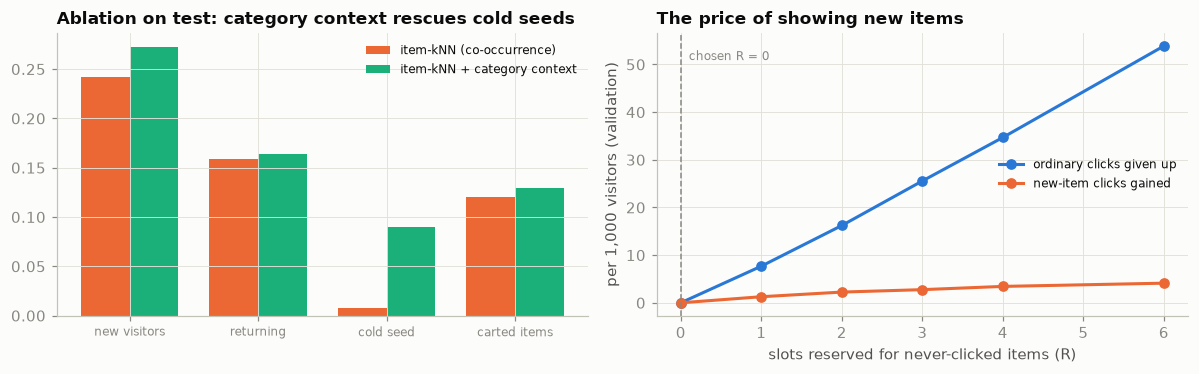

In [11]:
t0 = time.time()

def with_new_items(w, rec, cat, snapshot_at, R):
    '''Reserve the last R slots for never-clicked items in the seed's category: available first, most recently listed first.'''
    if R == 0:
        return rec
    av = asof("available", snapshot_at) if snapshot_at is not None else latest("available")
    li = listed[listed <= snapshot_at] if snapshot_at is not None else listed
    pool = pd.DataFrame({"cat": cat}).join(av.rename("avail")).join(li.rename("listed"), how="inner")
    pool = pool[~pool.index.isin(w.warm)].assign(avail=lambda d: d.avail.fillna(0))
    pool = pool.sort_values(["cat", "avail", "listed"], ascending=[True, False, False], kind="stable")
    pool = pool.assign(r=pool.groupby("cat").cumcount()).query("r < 3 * @R").reset_index(names="itemid")
    seed_cat = cat.reindex(w.vis.seed.values).fillna(-1).astype(int).values
    c = pd.DataFrame({"visitor": w.vis.visitor.values, "cat": seed_cat}).query("cat >= 0").merge(pool[["cat", "itemid", "r"]], on="cat")
    c = c[~pd.Index(KEY(c.visitor, c.itemid)).isin(w.excl)].sort_values(["visitor", "r"], kind="stable")
    c = c.assign(rr=c.groupby("visitor").cumcount()).query("rr < @R")
    n_new = c.groupby("visitor").size()
    base = rec[rec["rank"] < N_SLOTS - n_new.reindex(rec.visitor).fillna(0).values]
    new = c.assign(rank=N_SLOTS - n_new.reindex(c.visitor).values + c.rr)[["visitor", "itemid", "rank"]]
    return pd.concat([base, new], ignore_index=True).drop_duplicates(["visitor", "itemid"])

op = []
for R in NEW_ITEM_SLOTS:
    _, _, t = evaluate(VAL, with_new_items(VAL, base_val, cat_val, VALID_START, R))
    op.append({"R": R, "ordinary clicks": t.loc[~t.cold, "hit"].sum(), "new-item clicks": t.loc[t.cold, "hit"].sum()})
op = pd.DataFrame(op).set_index("R")
per_k = 1000 / len(VAL.vis)
op["value per 1,000 visitors"] = (op["ordinary clicks"] + NEW_ITEM_VALUE * op["new-item clicks"]) * per_k
op["ordinary clicks given up per new-item click (last slot added)"] = -op["ordinary clicks"].diff() / op["new-item clicks"].diff()
R_STAR = int(op["value per 1,000 visitors"].idxmax())
display(op.style.format({"ordinary clicks": "{:,.0f}", "new-item clicks": "{:,.0f}", "value per 1,000 visitors": "{:.1f}",
                         "ordinary clicks given up per new-item click (last slot added)": "{:.1f}"}, na_rep="–"))
CHOSEN = "item-kNN + category context" + (f" + {R_STAR} new-item slots" if R_STAR else "")
REC[CHOSEN] = with_new_items(TEST, REC["item-kNN + category context"], cat_test, TEST_START, R_STAR)
r_star = evaluate(TEST, REC[CHOSEN])[0]
print(f"chosen on validation at NEW_ITEM_VALUE = {NEW_ITEM_VALUE:g}: R = {R_STAR} → '{CHOSEN}' · test recall@20 {r_star['recall@20']:.3f}, "
      f"NDCG@20 {r_star['NDCG@20']:.3f}, hit rate on cold items {r_star['hit rate · cold items']:.3f} ({time.time()-t0:.0f}s)")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
ax = axes[0]
cols = ["recall@20 · new visitors", "recall@20 · returning", "recall@20 · cold seed", "hit rate · carted items"]
x = np.arange(len(cols))
for j, (name, color) in enumerate(zip(abl, [SERIES[1], SERIES[2]])):
    ax.bar(x + (j - 0.5) * 0.38, [abl[name][c] for c in cols], width=0.38, color=color, label=name)
ax.set_xticks(x); ax.set_xticklabels([c.split(" · ")[1] for c in cols], fontsize=8)
ax.set_title("Ablation on test: category context rescues cold seeds"); ax.legend(fontsize=8)
ax = axes[1]
ax.plot(op.index, (op["ordinary clicks"].iloc[0] - op["ordinary clicks"]) * per_k, "-o", color=SERIES[0], lw=2, label="ordinary clicks given up")
ax.plot(op.index, (op["new-item clicks"] - op["new-item clicks"].iloc[0]) * per_k, "-o", color=SERIES[1], lw=2, label="new-item clicks gained")
ax.axvline(R_STAR, color=MUTED, ls="--", lw=1); ax.text(R_STAR + 0.1, ax.get_ylim()[1] * 0.9, f"chosen R = {R_STAR}", color=MUTED, fontsize=8)
ax.set_xlabel("slots reserved for never-clicked items (R)"); ax.set_ylabel("per 1,000 visitors (validation)")
ax.set_title("The price of showing new items"); ax.legend(fontsize=8)
plt.tight_layout()

On validation the first reserved slot gives up 6.0 ordinary clicks per new-item click, and each further slot costs more (8.7 for the second, 13 to 28 after). At the assumed value of 5, **no slot is reserved**: the strip shipped is item-kNN plus category context. Above 6.0 the first slot pays; that number goes to the merchandising lead, in an ADR.

## 5 · The traps ⚠

*Part B · Given model · read; C1 turns each trap into a test.*

Four things a careless version of this notebook would have done.

**Trap 1 — item properties joined without an as-of rule.** Join the snapshot log on `itemid` alone and every event gets the item's *final* state: its category after the August re-filing (Section 6), its availability on 13 September.

In [12]:
share = pd.DataFrame({
    "as of the event (honest)": pd.Series(ev.avail.values == 1).groupby(ev.ev.values).mean().values,
    "latest snapshot (⚠ no as-of rule)": pd.Series(latest("available").reindex(ev.itemid.values).values == 1).groupby(ev.ev.values).mean().values,
}, index=EVENTS).T
print("share of events on items marked available"); display(share.style.format("{:.1%}"))
t0 = time.time()
R_DEMO = max(R_STAR, 2)
leaky_base, _, cat_leak = cf_plus_category(TEST, knn, pop_test, TEST_START, None)
trap1 = {"as of the cutoff (honest)": evaluate(TEST, with_new_items(TEST, REC["item-kNN + category context"], cat_test, TEST_START, R_DEMO))[0],
         "latest snapshot (⚠ leaks)": evaluate(TEST, with_new_items(TEST, leaky_base, cat_leak, None, R_DEMO))[0]}
print(f"item-kNN + category context + {R_DEMO} new-item slots on test, categories and availability read two ways:")
display(table({k: {c: v[c] for c in ["recall@20", "recall@20 · cold seed", "hit rate · cold items"]} for k, v in trap1.items()}))
print(f"cold seeds with a known category: as of {TEST_START:%d %b} {TEST.vis.seed.isin(cat_test.index)[TEST.vis.seed_cold].mean():.1%} · "
      f"latest snapshot {TEST.vis.seed.isin(cat_leak.index)[TEST.vis.seed_cold].mean():.1%} · "
      f"items first listed after the cutoff: {(listed > TEST_START).sum():,} ({time.time()-t0:.0f}s)")

share of events on items marked available


,view,addtocart,transaction
as of the event (honest),48.5%,84.2%,82.8%
latest snapshot (⚠ no as-of rule),36.6%,63.7%,61.4%


item-kNN + category context + 2 new-item slots on test, categories and availability read two ways:


,recall@20,recall@20 · cold seed,hit rate · cold items
as of the cutoff (honest),0.248,0.084,0.017
latest snapshot (⚠ leaks),0.253,0.107,0.054


cold seeds with a known category: as of 04 Sep 68.1% · latest snapshot 82.5% · items first listed after the cutoff: 3,309 (7s)


As of the event, 84 % of add-to-carts land on available items; from the last snapshot, 64 %. A team would conclude availability hardly matters, when it is a strong signal (probably carted items sell out; task C1 checks). Second, with two new-item slots so the effect shows: the leaky join triples the cold-item hit rate (0.054 against 0.017) and lifts cold-seed recall from 8.4 % to 10.7 %, because the final snapshot knows the categories of items filed after the cutoff (82.5 % of cold seeds against 68.1 %).

**Trap 2 — a random split of visitors.** Holding out 20 % of visitors looks rigorous, but the other 80 % keep all 4.5 months, test fortnight included. Honest: the same visitors, cut at 4 September.

**Trap 3 — extreme visitors left in.** A visitor with 3,000 items contributes nine million co-occurrence pairs.

**Trap 4 — scoring only what the model could have seen.** Scripts that drop unknown items and users drop the cold targets and cold seeds.

In [13]:
t0 = time.time()
# Trap 2 — hold out 20 % of visitors at random; the naive model trains on the other 80 % over all 4.5 months
held = pd.Index(rng.choice(ev.visitor.unique(), size=ev.visitor.nunique() // 5, replace=False))
in_held = ev.visitor.isin(held).values
RV = make_window(ev[ev.ts < TEST_START], ev[(ev.ts >= TEST_START) & in_held], "random 20 % of visitors")
trap2 = {}
for label, trn, at in [("naive", ev[~in_held], DATA_END), ("honest", ev[~in_held & (ev.ts < TEST_START).values], TEST_START)]:
    m_ = fit_knn(trn)
    trap2[label] = evaluate(RV, recommend(RV, knn_cands(RV, m_, W_HIST), popularity(trn, at, POP_DAYS)))[0]["recall@20"]
    trap2[label + " known"] = RV.tg.itemid.isin(m_.items).mean()
print(f"random 20 % of visitors ({len(RV.vis):,} scored in the test fortnight) · item-kNN recall@20: trained on all 4.5 months "
      f"{trap2['naive']:.3f} · cut at {TEST_START:%d %b} {trap2['honest']:.3f} · targets known to the model {trap2['naive known']:.1%} against "
      f"{trap2['honest known']:.1%} ({time.time()-t0:.0f}s)")
del m_

# Trap 3 — extreme visitors left in the training data
t0 = time.time()
knn_all = fit_knn(TEST.tr, cap=None, blocks=32)
r_all = evaluate(TEST, recommend(TEST, knn_cands(TEST, knn_all, W_HIST), pop_test))[0]
n_items = TEST.tr[["visitor", "itemid"]].drop_duplicates().groupby("visitor").size()
print(f"item-kNN trained with the {(n_items > MAX_ITEMS_PER_VISITOR).sum()} extreme visitors: recall@20 {r_all['recall@20']:.3f} "
      f"(capped: {res['item-kNN (co-occurrence)']['recall@20']:.3f}) · those visitors supply "
      f"{(n_items[n_items > MAX_ITEMS_PER_VISITOR] ** 2).sum() / (n_items ** 2).sum():.0%} of all co-occurrence pairs ({time.time()-t0:.0f}s)")
del knn_all

# Trap 4 — evaluating only on items, and seeds, the model could have seen
_, per_b, t_b = evaluate(TEST, REC[CHOSEN])
warm_only = t_b[~t_b.cold & ~t_b.visitor.isin(TEST.vis.visitor[TEST.vis.seed_cold])].groupby("visitor").hit.mean().mean()
print(f"{CHOSEN}: recall@20 on warm targets of warm-seed visitors {warm_only:.3f} against {per_b.recall.mean():.3f} on everything")

traps = pd.DataFrame([
    ["1 · properties without an as-of rule", f"new-item slots (R = {R_DEMO}): hit rate on cold items",
     trap1["latest snapshot (⚠ leaks)"]["hit rate · cold items"], trap1["as of the cutoff (honest)"]["hit rate · cold items"]],
    ["2 · random split of visitors", "item-kNN recall@20 (the 20 % held out)", trap2["naive"], trap2["honest"]],
    ["3 · extreme visitors kept", "item-kNN recall@20", r_all["recall@20"], res["item-kNN (co-occurrence)"]["recall@20"]],
    ["4 · cold items dropped from the test", "chosen model recall@20", warm_only, per_b.recall.mean()],
], columns=["trap", "metric", "naive", "honest"]).set_index("trap")
traps.style.format({"naive": "{:.3f}", "honest": "{:.3f}"})

random 20 % of visitors (4,976 scored in the test fortnight) · item-kNN recall@20: trained on all 4.5 months 0.245 · cut at 04 Sep 0.213 · targets known to the model 90.7% against 87.1% (8s)


item-kNN trained with the 111 extreme visitors: recall@20 0.195 (capped: 0.229) · those visitors supply 86% of all co-occurrence pairs (33s)
item-kNN + category context: recall@20 on warm targets of warm-seed visitors 0.274 against 0.256 on everything


,metric,naive,honest
trap,,,
1 · properties without an as-of rule,new-item slots (R = 2): hit rate on cold items,0.054,0.017
2 · random split of visitors,item-kNN recall@20 (the 20 % held out),0.245,0.213
3 · extreme visitors kept,item-kNN recall@20,0.195,0.229
4 · cold items dropped from the test,chosen model recall@20,0.274,0.256


Three traps flatter the model and one hurts it. The random split adds 3.2 points (0.245 against 0.213): the model has seen the test fortnight's co-views. Dropping cold cases adds 1.8 points. The extreme visitors *cost* 3.5 points (0.195 against 0.229): 111 visitors supply 86 % of all co-occurrence pairs. Since they make 23 % of purchases, whether they get their own strip is a commercial question (task E4).

# Part C — Productionise it

*Sections 6–10: this is your assignment.*

## 6 · After deployment: the catalogue moves under the model

*Part C · Productionise · what your monitoring plan must catch (C5); reuse `psi_by_week`; S3 replays the refits.*

Two clocks, as in Task 02. **Now**: churn, category mix and conversion by week. **Later**: recall@20 of a model frozen on 6 July against one retrained every Monday. The category mix is read *as of the event* and *with the taxonomy frozen at 6 July*, against the four weeks before 6 July.

In [14]:
t0 = time.time()
wk = ev.ts.dt.to_period("W-SUN")                                    # ISO weeks, Monday to Sunday
first_seen = ev.groupby("itemid").ts.transform("min")
views = ev.ev.values == 0
root_event = pd.Series(ev.cat.values).map(root_of).fillna(-1).astype(int).values
root_frozen = ev.itemid.map(asof("categoryid", FREEZE_DATE)).map(root_of).fillna(-1).astype(int).values

def psi_by_week(root):
    k = views & (root >= 0)
    mix = pd.crosstab(wk[k], root[k], normalize="index")
    ref = mix.loc[[w_ for w_ in mix.index if FREEZE_DATE - pd.Timedelta(days=28) <= w_.start_time < FREEZE_DATE]].mean()
    return pd.Series([float(np.sum((mix.loc[w_] - ref) * np.log((mix.loc[w_] + 1e-6) / (ref + 1e-6)))) for w_ in mix.index], index=mix.index)

pcat = props[props.prop == "categoryid"].sort_values(["itemid", "ts"], kind="stable")
prev = pcat.groupby("itemid").value.shift()
refiled = pcat[prev.notna() & (prev != pcat.value)]
weekly = pd.DataFrame({"week": wk, "view": views, "cart": ev.ev.values == 1, "new_item": (first_seen.dt.to_period("W-SUN") == wk).values}
                      ).groupby("week").agg(events=("view", "size"), views=("view", "sum"), carts=("cart", "sum"), new_item_share=("new_item", "mean"))
weekly["view-to-cart"] = weekly.carts / weekly.views
weekly["items re-filed"] = refiled.ts.dt.to_period("W-SUN").value_counts().reindex(weekly.index).fillna(0).astype(int)
weekly["PSI · as of the event"] = psi_by_week(root_event)
weekly["PSI · taxonomy frozen 6 Jul"] = psi_by_week(root_frozen)
shown = weekly[weekly.index.start_time >= pd.Timestamp("2015-06-01")]
display(shown.iloc[::2][["events", "view-to-cart", "new_item_share", "items re-filed", "PSI · as of the event", "PSI · taxonomy frozen 6 Jul"]].style.format(
    {"events": "{:,.0f}", "view-to-cart": "{:.2%}", "new_item_share": "{:.1%}", "items re-filed": "{:,.0f}",
     "PSI · as of the event": "{:.3f}", "PSI · taxonomy frozen 6 Jul": "{:.3f}"}))
rf = refiled.assign(r0=prev[refiled.index].map(root_of), r1=refiled.value.map(root_of))
above = shown.index[shown["PSI · as of the event"] >= 0.10]
print(f"PSI as of the event: first week ≥ 0.10 {above[0].start_time:%d %b}, max {shown['PSI · as of the event'].max():.3f} · "
      f"taxonomy frozen 6 Jul: max {shown['PSI · taxonomy frozen 6 Jul'].max():.3f} · view-to-cart {shown['view-to-cart'].min():.2%}–{shown['view-to-cart'].max():.2%} · "
      f"largest re-filing snapshots: {', '.join(f'{d:%d %b} ({n:,})' for d, n in refiled.groupby('ts').size().nlargest(3).items())}")
print(f"re-filings: {len(rf):,}, of which {(rf.r0 != rf.r1).mean():.0%} move the item to another top-level category; "
      f"the largest source is root {int(rf.r0.value_counts().index[0])} ({rf.r0.value_counts().iloc[0]:,} moves) · ({time.time()-t0:.0f}s)")

,events,view-to-cart,new_item_share,items re-filed,PSI · as of the event,PSI · taxonomy frozen 6 Jul
week,,,,,,
2015-06-01/2015-06-07,"146,426",2.39%,12.4%,476,0.011,0.007
2015-06-15/2015-06-21,"145,957",2.86%,10.1%,0,0.005,0.006
2015-06-29/2015-07-05,"139,211",2.46%,8.7%,"2,440",0.009,0.005
2015-07-13/2015-07-19,"152,214",2.50%,6.9%,"1,317",0.034,0.011
2015-07-27/2015-08-02,"144,304",2.77%,5.8%,37,0.035,0.024
2015-08-10/2015-08-16,"120,730",2.66%,5.6%,"2,394",0.129,0.021
2015-08-24/2015-08-30,"127,794",2.92%,5.2%,408,0.219,0.047
2015-09-07/2015-09-13,"138,773",2.63%,5.4%,508,0.251,0.057


PSI as of the event: first week ≥ 0.10 10 Aug, max 0.255 · taxonomy frozen 6 Jul: max 0.063 · view-to-cart 2.39%–2.92% · largest re-filing snapshots: 09 Aug (8,595), 23 Aug (5,276), 05 Jul (2,440)
re-filings: 25,619, of which 78% move the item to another top-level category; the largest source is root 250 (15,667 moves) · (2s)


last four weeks, mean recall@20: frozen 0.172 (first week 0.230, -25%) · retrained weekly 0.247 · weekly refits 83s


,visitors scored,frozen on 6 Jul,retrained weekly,targets known to the frozen model
week,,,,
2015-07-06 00:00:00,"14,570",0.230,0.230,86.8%
2015-07-13 00:00:00,"13,782",0.222,0.237,87.1%
2015-07-20 00:00:00,"17,808",0.175,0.196,81.7%
2015-07-27 00:00:00,"13,740",0.187,0.246,83.1%
2015-08-03 00:00:00,"11,778",0.194,0.234,82.2%
2015-08-10 00:00:00,"10,992",0.189,0.239,82.0%
2015-08-17 00:00:00,"11,933",0.184,0.243,80.7%
2015-08-24 00:00:00,"12,044",0.179,0.239,78.3%
2015-08-31 00:00:00,"11,215",0.179,0.246,78.8%


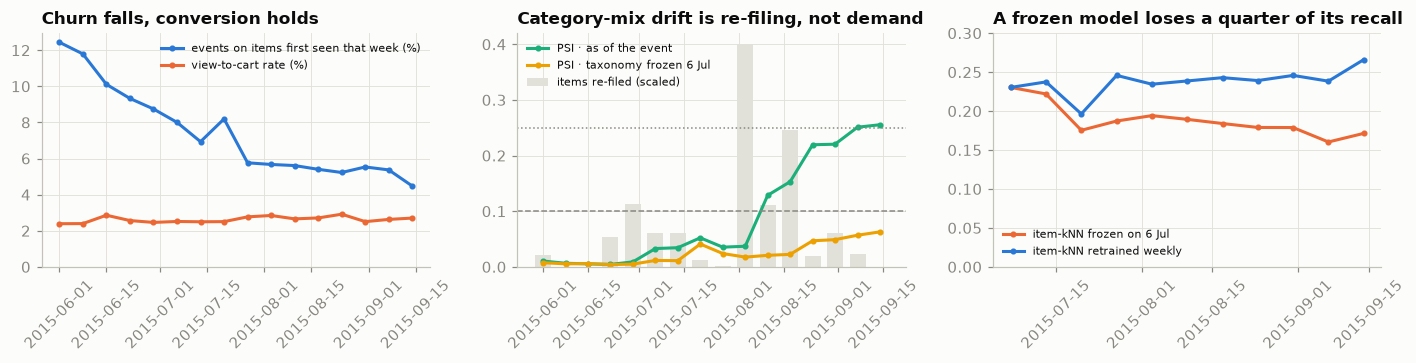

In [15]:
t0 = time.time()
weeks = pd.date_range(FREEZE_DATE, DATA_END, freq="7D")
frozen = fit_knn(ev[ev.ts < FREEZE_DATE]); pop_frozen = popularity(ev[ev.ts < FREEZE_DATE], FREEZE_DATE, POP_DAYS)
decay = []
for a in weeks:
    b = min(a + pd.Timedelta(days=7), DATA_END + pd.Timedelta(hours=1))
    w = make_window(ev[ev.ts < a], ev[(ev.ts >= a) & (ev.ts < b)], f"{a:%d %b}")
    fresh = fit_knn(w.tr); pop_fresh = popularity(w.tr, a, POP_DAYS)
    decay.append({"week": a, "visitors scored": len(w.vis),
                  "frozen on 6 Jul": evaluate(w, recommend(w, knn_cands(w, frozen, W_HIST), pop_frozen))[0]["recall@20"],
                  "retrained weekly": evaluate(w, recommend(w, knn_cands(w, fresh, W_HIST), pop_fresh))[0]["recall@20"],
                  "targets known to the frozen model": w.tg.itemid.isin(frozen.items).mean()})
decay = pd.DataFrame(decay).set_index("week")
last4 = decay.iloc[-4:]
print(f"last four weeks, mean recall@20: frozen {last4['frozen on 6 Jul'].mean():.3f} (first week {decay['frozen on 6 Jul'].iloc[0]:.3f}, "
      f"{last4['frozen on 6 Jul'].mean() / decay['frozen on 6 Jul'].iloc[0] - 1:+.0%}) · retrained weekly {last4['retrained weekly'].mean():.3f} · weekly refits {time.time()-t0:.0f}s")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
t_ = shown.index.to_timestamp()
ax = axes[0]
ax.plot(t_, shown.new_item_share * 100, "-o", ms=3, lw=2, color=SERIES[0], label="events on items first seen that week (%)")
ax.plot(t_, shown["view-to-cart"] * 100, "-o", ms=3, lw=2, color=SERIES[1], label="view-to-cart rate (%)")
ax.set_ylim(0, None); ax.set_title("Churn falls, conversion holds"); ax.legend(fontsize=7); ax.tick_params(axis="x", rotation=45)
ax = axes[1]
ax.bar(t_, shown["items re-filed"] / shown["items re-filed"].max() * 0.4, width=5, color=GRID, label="items re-filed (scaled)")
ax.plot(t_, shown["PSI · as of the event"], "-o", ms=3, lw=2, color=SERIES[2], label="PSI · as of the event")
ax.plot(t_, shown["PSI · taxonomy frozen 6 Jul"], "-o", ms=3, lw=2, color=SERIES[3], label="PSI · taxonomy frozen 6 Jul")
ax.axhline(0.10, color=MUTED, ls="--", lw=1); ax.axhline(0.25, color=MUTED, ls=":", lw=1)
ax.set_title("Category-mix drift is re-filing, not demand"); ax.legend(fontsize=7); ax.tick_params(axis="x", rotation=45)
ax = axes[2]
ax.plot(decay.index, decay["frozen on 6 Jul"], "-o", ms=3, lw=2, color=SERIES[1], label="item-kNN frozen on 6 Jul")
ax.plot(decay.index, decay["retrained weekly"], "-o", ms=3, lw=2, color=SERIES[0], label="item-kNN retrained weekly")
ax.set_ylim(0, 0.3); ax.set_title("A frozen model loses a quarter of its recall"); ax.legend(fontsize=7); ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
decay.style.format({"visitors scored": "{:,.0f}", "frozen on 6 Jul": "{:.3f}", "retrained weekly": "{:.3f}", "targets known to the frozen model": "{:.1%}"})

**Churn** settles as the log matures: events on items first seen that week fall from 12.4 % in early June to 5.4 % in September. **Conversion** has no trend (view-to-cart 2.39–2.92 %). **The category mix** is the lesson. As of each event, its PSI crosses 0.10 in the week of 10 August and reaches 0.255; with the taxonomy frozen at 6 July it never passes 0.063. The shop re-filed 25,619 items, 78 % into another top-level category and most out of root 250, in batches on 9 and 23 August. Visitors did not change what they browse; the catalogue changed what it calls it. Monitor both lines: a re-filing breaks category features and dashboards as surely as a shift in demand does.

Frozen on 6 July, item-kNN averages 0.172 over the last four weeks against 0.230 in its first (−25 %), while the weekly refit holds 0.25; by September the frozen model knows only 74 % of what visitors click. Retrain weekly, alarm on the known-target share, refit after any re-filing.

## 7 · Merchandiser questions, answered without an LLM

*Part C · Productionise · package the merchandiser question layer (`parse`, `run_sql`) with its golden set; E2 and S1 build on it.*

Task 04's lesson carries over: once a question is parsed into an *intent* and *slots* (period, category, item, event type), the answer is a parameterised SQL query. Periods and ids come from patterns, intents from keyword rules written against a *development* set of phrasings. A category means its subtree, via a closure table DuckDB derives with a recursive query. Two refusals are built in: periods outside the data, and **any question about an individual visitor**.

In [16]:
con = duckdb.connect()
con.execute(f"SET threads={N_JOBS}")
con.register("ev_df", ev[["ts", "visitor", "ev", "itemid", "order_id", "cat"]])
con.execute("CREATE TABLE events AS SELECT ts, visitor, CASE ev WHEN 0 THEN 'view' WHEN 1 THEN 'addtocart' ELSE 'transaction' END AS event, "
            "itemid, order_id, cat FROM ev_df")
con.register("tree_df", tree)
con.execute("""CREATE TABLE cat_closure AS
    WITH RECURSIVE c(ancestor, descendant) AS (
        SELECT categoryid, categoryid FROM tree_df
        UNION ALL SELECT c.ancestor, t.categoryid FROM c JOIN tree_df t ON t.parentid = c.descendant)
    SELECT * FROM c""")
SQL = {   # one parameterised query per intent; a category filter walks the taxonomy through the closure table
    "count_cat": "SELECT count(*) FROM events e JOIN cat_closure c ON e.cat = c.descendant WHERE c.ancestor = $cat AND e.event = $event AND e.ts >= $a AND e.ts < $b",
    "rate_cat": "SELECT count(*) FILTER (WHERE event = 'addtocart') / count(*) FILTER (WHERE event = 'view') FROM events e JOIN cat_closure c ON e.cat = c.descendant WHERE c.ancestor = $cat AND e.ts >= $a AND e.ts < $b",
    "top_items": "SELECT itemid FROM events WHERE event = $event AND ts >= $a AND ts < $b GROUP BY itemid ORDER BY count(*) DESC, itemid LIMIT 5",
    "buyers_item": "SELECT count(DISTINCT visitor) FROM events WHERE itemid = $item AND event = 'transaction' AND ts >= $a AND ts < $b",
    "top_category": "SELECT cat FROM events WHERE event = $event AND cat >= 0 AND ts >= $a AND ts < $b GROUP BY cat ORDER BY count(*) DESC, cat LIMIT 1",
    "first_seen": "SELECT count(*) FROM (SELECT itemid, min(ts) AS f FROM events GROUP BY itemid) WHERE f >= $a AND f < $b",
    "orders": "SELECT count(DISTINCT order_id) FROM events WHERE event = 'transaction' AND ts >= $a AND ts < $b",
}
NEEDS = {"count_cat": ["cat", "event"], "rate_cat": ["cat"], "top_items": ["event"], "buyers_item": ["item"], "top_category": ["event"],
         "first_seen": [], "orders": []}
EVENT_WORDS = {"views": "view", "viewed": "view", "add-to-carts": "addtocart", "added to cart": "addtocart",
               "purchases": "transaction", "bought": "transaction", "purchased": "transaction"}   # written against the dev phrasings
INTENT_RULES = [("rate_cat", ["view-to-cart"]), ("orders", ["orders"]), ("first_seen", ["for the first time"]),
                ("buyers_item", ["how many visitors"]), ("top_category", ["which category"]), ("top_items", ["which five items"]),
                ("count_cat", ["how many", "number of"])]   # first match wins
MONTHS = {m.lower(): i for i, m in enumerate(calendar.month_name) if m} | {m.lower(): i for i, m in enumerate(calendar.month_abbr) if m}
DATA_START = ev.ts.min()

def parse_period(q):
    ql = q.lower()
    if m := re.search(r"between (\d{4}-\d{2}-\d{2}) and (\d{4}-\d{2}-\d{2})", ql):
        return pd.Timestamp(m.group(1)), pd.Timestamp(m.group(2)) + pd.Timedelta(days=1)
    if m := re.search(r"\b(" + "|".join(sorted(MONTHS, key=len, reverse=True)) + r")\s+(20\d\d)\b", ql):
        a = pd.Timestamp(int(m.group(2)), MONTHS[m.group(1)], 1); return a, a + pd.DateOffset(months=1)
    return None

def parse(q: str) -> dict:
    '''Deterministic query understanding: refusals first, then the period, ids by pattern, the intent by keyword rule.'''
    ql = q.lower()
    if re.search(r"\bvisitor\s+\d+|\bwhich visitor|\bwho\b", ql):
        return {"status": "refused: visitor-level"}          # governance: aggregates only, no individual profiles
    period = parse_period(q)
    if period is None:
        return {"status": "not understood"}
    if period[1] <= DATA_START or period[0] > DATA_END:
        return {"status": "refused: outside the data"}
    ents = {"a": period[0], "b": period[1]}
    if m := re.search(r"\bcategory (\d+)", ql): ents["cat"] = int(m.group(1))
    if m := re.search(r"\bitem (\d+)", ql): ents["item"] = int(m.group(1))
    if found := [e for w_, e in EVENT_WORDS.items() if w_ in ql]: ents["event"] = found[0]
    for intent, words in INTENT_RULES:
        if any(w_ in ql for w_ in words) and all(n in ents for n in NEEDS[intent]):
            return {"status": "ok", "intent": intent, "slots": {k: ents[k] for k in NEEDS[intent] + ["a", "b"]}}
    return {"status": "not understood"}

def run_sql(p):
    r = con.execute(SQL[p["intent"]], p["slots"]).fetchall()
    return [x[0] for x in r] if p["intent"] == "top_items" else r[0][0]

for q in ["How many add-to-carts did category 1051 get in August 2015?", "Which visitor bought the most in July 2015?",
          "What was the cart conversion of category 1051 in Aug 2015?"]:
    p = parse(q)
    print(f"{q!r:66s} → {p['status']}" + (f" · {p['intent']} {({k: (f'{v:%d %b}' if isinstance(v, pd.Timestamp) else v) for k, v in p['slots'].items()})} "
                                         f"→ {run_sql(p):,}" if p["status"] == "ok" else ""))

'How many add-to-carts did category 1051 get in August 2015?'      → ok · count_cat {'cat': 1051, 'event': 'addtocart', 'a': '01 Aug', 'b': '01 Sep'} → 464
'Which visitor bought the most in July 2015?'                      → refused: visitor-level
'What was the cart conversion of category 1051 in Aug 2015?'       → not understood


**A golden set the rules have not seen**, generated from the data as in Task 04: eight intents (one must be refused) × three slot fills (one outside the data, one a date range) × four phrasings. Two phrasings per intent are the development set; two were written separately and never used to tune the rules. The truth is computed **in pandas, independently of the SQL** (subtrees from networkx). The parser's author wrote both sets, and 5 of the 16 held-out templates repeat a development template with another event word or date format, so the held-out set mostly tests synonyms and date formats (task E2).

In [17]:
desc = {n: nx.descendants(G, n) | {n} for n in G}
def truth(intent, s):
    w = ev[(ev.ts >= s["a"]) & (ev.ts < s["b"])]
    code = EVENTS.index(s["event"]) if "event" in s else None
    if intent == "count_cat": return int(((w.ev == code) & w.cat.isin(desc[s["cat"]])).sum())
    if intent == "rate_cat":
        x = w[w.cat.isin(desc[s["cat"]])]; return (x.ev == 1).sum() / (x.ev == 0).sum()
    if intent == "top_items":
        c = w[w.ev == code].groupby("itemid").size(); return list(c.sort_index().sort_values(ascending=False, kind="stable").index[:5])
    if intent == "buyers_item": return int(w.loc[(w.itemid == s["item"]) & (w.ev == 2), "visitor"].nunique())
    if intent == "top_category":
        c = w[(w.ev == code) & (w.cat >= 0)].groupby("cat").size(); return int(c.sort_index().sort_values(ascending=False, kind="stable").index[0])
    if intent == "first_seen": return int(((first_seen >= s["a"]) & (first_seen < s["b"])).groupby(ev.itemid).first().sum())
    if intent == "orders": return int(w.loc[w.ev == 2, "order_id"].nunique())

DEV = {   # phrasings the rules were written against
    "count_cat": ["How many {ev} did category {cat} get {per}?", "Number of {ev} in category {cat} {per}?"],
    "rate_cat": ["What was the view-to-cart rate of category {cat} {per}?", "View-to-cart rate for category {cat} {per}?"],
    "top_items": ["Which five items had the most {ev} {per}?", "Which five items got the most {ev} {per}?"],
    "buyers_item": ["How many visitors bought item {item} {per}?", "How many visitors purchased item {item} {per}?"],
    "top_category": ["Which category had the most {ev} {per}?", "Which category got the most {ev} {per}?"],
    "first_seen": ["How many items were viewed for the first time {per}?", "Number of items viewed for the first time {per}?"],
    "orders": ["How many orders were placed {per}?", "Number of orders {per}?"],
    "refuse": ["What did visitor {vis} buy {per}?", "Which visitor bought the most {per}?"],
}
HELD_OUT = {   # written separately, as a merchandiser might type them; the rules were not tuned on these
    "count_cat": ["Total {ev2} for category {cat}, {per2}?", "How many {ev2} came from category {cat} {per2}?"],
    "rate_cat": ["What share of views in category {cat} turned into add-to-carts {per2}?", "Cart conversion of category {cat} {per2}?"],
    "top_items": ["Top 5 items by {ev2} {per2}?", "Which five items had the most {ev2} {per2}?"],
    "buyers_item": ["How many visitors bought item {item} {per2}?", "Number of distinct buyers of item {item} {per2}?"],
    "top_category": ["Which category led on {ev2} {per2}?", "Which category had the most {ev2} {per2}?"],
    "first_seen": ["How many products got their first ever view {per2}?", "How many items were viewed for the first time {per2}?"],
    "orders": ["How many orders were placed {per2}?", "Order count {per2}?"],
    "refuse": ["Show me everything visitor {vis} viewed {per2}.", "Who were our biggest buyers {per2}?"],
}
EV_PHRASE = {"view": ("views", "page views"), "addtocart": ("add-to-carts", "basket adds"), "transaction": ("purchases", "sales")}
cat_n = ev.cat.value_counts()
top_cats = pd.Series({n: cat_n.reindex(list(desc[n])).sum() for n in G}).sort_values(ascending=False)   # events per category subtree
gold = []
for intent in DEV:
    for k in range(3):
        mth = int(rng.integers(5, 10)); a = pd.Timestamp(2015, mth, 1)
        if k == 2 and intent != "refuse":
            mth = [3, 4, 10][int(rng.integers(3))]; a = pd.Timestamp(2015, mth, 1)      # one fill in three is outside the data
        b = a + pd.DateOffset(months=1)
        if k == 1:                                                                        # a date range instead of a month
            a = pd.Timestamp(2015, mth, int(rng.integers(1, 10))); b = a + pd.Timedelta(days=int(rng.integers(7, 15)))
        e_ = EVENTS[int(rng.integers(3))]
        c_ = int(top_cats.index[int(rng.integers(0, 60))])
        bought = ev[(ev.ev == 2) & (ev.ts >= a) & (ev.ts < b)].itemid
        it_ = int(bought.sample(1, random_state=int(rng.integers(1e6))).iloc[0]) if len(bought) else int(ev.itemid.iloc[0])
        slots = {"a": a, "b": b, "event": e_, "cat": c_, "item": it_}
        inside = b > DATA_START and a <= DATA_END
        expect = "refused: visitor-level" if intent == "refuse" else ("answer" if inside else "refused: outside the data")
        tr_ = truth(intent, {kk: slots[kk] for kk in NEEDS[intent] + ["a", "b"]}) if expect == "answer" else None
        per = f"in {calendar.month_name[a.month]} {a.year}" if k != 1 else f"between {a:%Y-%m-%d} and {(b - pd.Timedelta(days=1)):%Y-%m-%d}"
        per2 = f"in {calendar.month_abbr[a.month]} {a.year}" if k != 1 else f"from {a:%d %b} to {(b - pd.Timedelta(days=1)):%d %b %Y}"
        fill = {"ev": EV_PHRASE[e_][0], "ev2": EV_PHRASE[e_][1], "cat": c_, "item": it_, "vis": int(rng.integers(1e6)), "per": per, "per2": per2}
        for split, bank in [("dev", DEV), ("held-out", HELD_OUT)]:
            for tmpl in bank[intent]:
                gold.append({"intent": intent, "split": split, "expect": expect, "truth": tr_, "question": tmpl.format(**fill)})
gold = pd.DataFrame(gold)
dev_templates = [t for v in DEV.values() for t in v]
n_repeat = sum(t.replace("{ev2}", "{ev}").replace("{per2}", "{per}") in dev_templates for v in HELD_OUT.values() for t in v)
print(f"held-out templates that repeat a development template, only the event word and date format changed: "
      f"{n_repeat} of {sum(len(v) for v in HELD_OUT.values())}")

def same(a, b):
    if isinstance(a, list) or isinstance(b, list): return list(a) == list(b)
    return a is not None and b is not None and abs(float(a) - float(b)) < 1e-9

rows, lat = [], []
for g in gold.itertuples():
    p = parse(g.question)
    if p["status"] == "ok":
        t1 = time.perf_counter(); ans = run_sql(p); lat.append((time.perf_counter() - t1) * 1000)
        outcome = "correct answer" if g.expect == "answer" and same(ans, g.truth) else "wrong answer"
    elif p["status"] == g.expect:
        outcome = "correct refusal"
    else:
        outcome = "not understood" if p["status"] == "not understood" else "wrong refusal"
    rows.append({"intent": g.intent, "split": g.split, "outcome": outcome, "question": g.question,
                 "read as": f"{p['intent']} {p['slots']['a']:%d %b}–{p['slots']['b'] - pd.Timedelta(days=1):%d %b}" if p["status"] == "ok" else p["status"]})
qa = pd.DataFrame(rows)
print(f"{len(gold)} questions · {gold.split.value_counts().to_dict()} · expect an answer {(gold.expect == 'answer').sum()}, "
      f"a refusal {(gold.expect != 'answer').sum()} · SQL latency median {np.median(lat):.0f} ms, max {np.max(lat):.0f} ms")
display(pd.crosstab(qa.split, qa.outcome).assign(total=lambda d: d.sum(axis=1)))
display(qa[(qa.split == "held-out") & (qa.outcome == "not understood")].groupby("intent").question.first().to_frame("a held-out phrasing not understood"))
print("wrong answers, with how the parser read them:")
display(qa[qa.outcome == "wrong answer"][["split", "question", "read as"]].set_index("split"))

held-out templates that repeat a development template, only the event word and date format changed: 5 of 16


96 questions · {'dev': 48, 'held-out': 48} · expect an answer 56, a refusal 40 · SQL latency median 14 ms, max 290 ms


outcome,correct answer,correct refusal,not understood,wrong answer,total
split,,,,,
dev,28,20,0,0,48
held-out,8,20,18,2,48


,a held-out phrasing not understood
intent,
buyers_item,Number of distinct buyers of item 21320 in Jun 2015?
count_cat,"Total page views for category 580, in May 2015?"
first_seen,How many products got their first ever view in May 2015?
orders,Order count in Jul 2015?
rate_cat,What share of views in category 1051 turned into add-to-carts in May 2015?
top_category,Which category led on sales in Jul 2015?
top_items,Top 5 items by page views in Jul 2015?


wrong answers, with how the parser read them:


,question,read as
split,,
held-out,How many items were viewed for the first time from 04 Sep to 12 Sep 2015?,first_seen 01 Sep–30 Sep
held-out,How many orders were placed from 03 Aug to 16 Aug 2015?,orders 01 Aug–31 Aug


On development phrasings the layer answers all 28 answerable questions and makes all 20 refusals. On held-out phrasings it answers 8 of 28, declines 18 ("Top 5 items", "sales", "first ever view", "Order count") and makes all 20 refusals. It also gives **2 wrong answers**: "from 03 Aug to 16 Aug 2015" is read as all of August, because the month pattern finds "Aug 2015" inside a range it does not know. A rule-based parser fails quietly when it half-understands: echo the reading beside every answer, and refuse when a date-like token is left over (task C1).

## 8 · The module spine for this project

*Part C · Productionise · the targets your system must meet, with this notebook's numbers.*

The card's nine rows, updated with this notebook's findings. Gate and alert thresholds must come from the business, in ADRs.

| Spine | In this project |
|---|---|
| Package and container (S02–S03) | `src/recs/` (`data.py` with as-of joins, `window.py`, `models/`, `serve.py`); `POST /recommend {seed, history}`; compose with Postgres holding the neighbour table (30 MB) |
| Monitoring (S04) | Latency. Now: share of targets the model knows (87 % → 74 % in ten weeks frozen), items shown (81,115 a fortnight), category-mix PSI both ways. Later: last week's recall@20 |
| CI/CD gate (S05) | recall@20 on the fingerprinted test fortnight (0.256); no join reads a later snapshot; batch–request parity (1,000 of 1,000) |
| MLflow tracking and registry (S06) | Look-back (14 days), history weight (0.25), neighbours (100), visitor cap (200), snapshot date; metrics by segment; taxonomy version |
| Offline / online training and serving | Nightly neighbour table (seconds to fit); request-time scoring from the seed; weekly refit holds recall@20 near 0.25, frozen falls to 0.17 |
| Data and model drift | 5–12 % of weekly events on never-seen items; 25,619 items re-filed (PSI 0.255 as of the event, ≤ 0.063 with a frozen taxonomy) |
| Knowledge base and context (S07–S09) | SKOS taxonomy (1,669 categories) with SHACL; 18 % of sampled items lack a category at the cutoff. Ablation: recall@20 0.229 → 0.256, cold seeds 0.008 → 0.090 |
| GenAI and context engineering (S10–S11) | LLM-written SQL re-run against the golden set (template parser: 8 of 28 held-out, 2 wrong); visitor-level questions refused |
| Governance | CC BY-NC-SA 4.0 (non-commercial); visitor ids replaced by a keyed hash, key in a secret store (the teaching default is public); the questions below; the heavy-visitor rule (23 % of purchases) needs an owner |

**Governance questions for you** (answer in an ADR; mark legal readings as readings):

1. **Consent.** ePrivacy Art. 5(3) requires consent to store or read information on a visitor's device unless strictly necessary for a service they asked for. Is a recommendation cookie strictly necessary? If not, what do visitors who declined see, and are they kept out of training?
2. **Profiling.** GDPR Art. 4(4) defines profiling; Art. 21 gives a right to object to processing based on legitimate interests. Which lawful basis applies, and how does an objection reach the nightly batch?
3. **Platform rules.** If the shop is an online platform under the DSA, Art. 27 requires its recommenders' main parameters to be explained (Art. 38: a non-profiling option on very large platforms). Does either apply?
4. **Retention.** How long may the log keep a visitor's history, and does deletion remove their co-occurrence pairs?
5. **Pseudonyms.** Who holds the hashing key, and who may ever join a pseudonym back to a cookie id?

## 9 · Student tasks

*Part C · Productionise · your assignment.*

This is an individual assignment: you pick one task from the catalogue, claimed first come, first served, so no other student works on it. **The model is given:** you package, evaluate, deploy and monitor this notebook's model; you do not design, tune or replace it. Where a task re-runs training (removing a leaking input, a retraining policy, a knowledge-base ablation), run the notebook's own training code with only its inputs or configuration changed. Work in your own repository, not in this notebook. Promote code into the `src/` package layout from Session 02, keep the notebook as a thin client, and record each design decision as an ADR in `docs/decisions/`. **Required:** all *Core* tasks (C1–C5), all *Extension* tasks (E1–E4) and Stretch **S1**, the GenAI task (Sessions 10–11). No API key is provided: run it on a local open-weight model, with a free hosted tier as an optional comparison, under the data rule for this task in [`docs/llm-access.md`](docs/llm-access.md). The other Stretch tasks are optional and count only towards the top band. The mark rewards the quality of each task, not the number done; the criteria are in `docs/task-rubric.md`.

### Core

- **C1 — Find and fix every trap.** As-of joins with a test that fails on a later snapshot; the visitor cap as a tested rule; time-only splits; cold cases kept. Check Trap 1's reading (do carted items sell out?) and add the parser guard against leftover dates.
- **C2 — Reproduce and freeze the given model.** Package the notebook's own data loading, features, training and scoring unchanged, retrain from a fresh clone with `SEED`, and show that your pipeline reproduces the numbers listed under *How this notebook is organised* within a tolerance you state. Add a data contract on the raw inputs (schema and value ranges, for example with pandera) and record any difference from the notebook in an ADR. No new features, learners or tuning.
- **C3 — Own the operating point.** Vary `NEW_ITEM_VALUE` (1–20), `N_SLOTS` (10–30) and `EVENT_WEIGHT`; show how R and the test numbers move; record the signed-off value in an ADR.
- **C4 — Package and gate.** `src/recs/`, `POST /recommend`, compose with Postgres; `make ci` gates on recall@20 against the fingerprinted fortnight and runs the as-of and parity tests (Sessions 02, 03, 05).
- **C5 — Register, document, monitor.** MLflow runs with segment metrics, snapshot date and taxonomy version; a `champion` alias; a model card (logging bias, licence, heavy-visitor rule); a monitoring plan with the known-target share, both PSI lines and Section 6's retraining policy (Sessions 04, 06).

### Extension

- **E1 — Knowledge-base ablation, extended (Sessions 07–09).** Version the category taxonomy and the dated item-property table, validate them with SHACL, and re-run the notebook's category back-off with and without KB context on cold seeds, reporting the gain per KB version.
- **E2 — An independent held-out set.** Someone other than you writes 40 merchandiser questions; extend the parser from the development set only; report accuracy, wrong answers and refusals.
- **E3 — Consent and profiling.** Simulate a 30 % opt-out (out of training, served category context); measure the cost for both groups; write your ePrivacy and GDPR reading of the four questions above.
- **E4 — The heavy visitors.** Describe the 118 visitors above the cap without identifying anyone, measure what the given strip shows them, and decide in an ADR between a B2B channel, a rule-based reorder list or nothing (no new model).

### Stretch

- **S1 — GenAI merchandiser assistant.** An LLM gets the schema, the closure table and three examples and returns `{sql, reading}`; re-run the SQL against the pandas truth on this golden set and E2's, refusing on disagreement or visitor-level questions. Report accuracy, wrong answers, prompt-injection tests and cost per answer (Sessions 10–11).
- **S2 — Online session re-ranking, costed.** Serve from Postgres or Redis, re-ranking as each view becomes a seed; report p50 and p99 latency and cost per 1,000 requests.
- **S3 — Retraining policy.** Replay Section 6 with daily, weekly and drift-triggered refits; compare recall gained with compute spent, including the August re-filing.

## 10 · Hand-in checklist

*Part C · Productionise · tick every box before you submit.*

- [ ] Repository in the Session 02 layout; fresh-clone test passes; `data/` and the pseudonym key not in Git
- [ ] `README.md` states the licence (non-commercial), the windows and how to obtain the data
- [ ] Forward evaluation only; as-of joins tested; visitor cap documented; cold cases kept
- [ ] Operating point from a stated value, with the ADR
- [ ] CI with the recall@20 gate, as-of and parity tests; registered model, model card, monitoring plan
- [ ] Question layer with its golden set and wrong-answer rate in CI
- [ ] Required tasks done: C1–C5, E1–E4 and S1
- [ ] GenAI task runs on a local model; any hosted run follows the data rule and logs provider, model and cost
- [ ] Reflective diary entry: what you chose, what you rejected, what evidence would change your mind

---

### Appendix — environment and references

- Python ≥ 3.11; `pandas`, `pyarrow`, `scipy`, `scikit-learn`, `duckdb`, `networkx`, `rdflib`, `pyshacl`, `matplotlib`, `kagglehub` (pinned in `requirements.txt`); no LLM. On a small laptop, lower `MF_RANK` or skip Section 6's weekly replay; the property cache is built once, streamed in 32 MB blocks.
- Retailrocket. *Retailrocket recommender system dataset.* Kaggle `retailrocket/ecommerce-dataset`, CC BY-NC-SA 4.0.
- Linden, G., Smith, B., York, J. (2003). Amazon.com recommendations: item-to-item collaborative filtering. *IEEE Internet Computing*.
- Hu, Y., Koren, Y., Volinsky, C. (2008). Collaborative filtering for implicit feedback datasets. *ICDM*.
- Cremonesi, P., Koren, Y., Turrin, R. (2010). Performance of recommender algorithms on top-N recommendation tasks. *RecSys*.
- Ludewig, M., Jannach, D. (2018). Evaluation of session-based recommendation algorithms. *UMUAI*.
- Directive 2002/58/EC (ePrivacy), Art. 5(3); Regulation (EU) 2016/679 (GDPR), Arts. 4(4), 21, Recital 26; Regulation (EU) 2022/2065 (Digital Services Act), Arts. 27, 38.

In [18]:
print(f"python packages · pandas {pd.__version__} · numpy {np.__version__} · scipy {scipy.__version__} · scikit-learn {sklearn.__version__} · "
      f"duckdb {duckdb.__version__} · networkx {nx.__version__} · rdflib {rdflib.__version__} · pyshacl {pyshacl.__version__} · pyarrow {pa.__version__}")
print(f"notebook finished · total wall time {time.time()-T_START:.0f}s")

python packages · pandas 3.1.0 · numpy 2.5.4 · scipy 1.18.1 · scikit-learn 1.9.1 · duckdb 2.0.0 · networkx 3.7 · rdflib 7.6.0 · pyshacl 0.40.1 · pyarrow 26.0.0
notebook finished · total wall time 237s
